In [1]:
import cv2
import numpy as np
import pandas as pd
import matplotlib
import skimage
import scipy
import sklearn
import tensorflow as tf
import keras
import networkx as nx
import skan
import patchify
from PIL import Image

2026-09-12 10:22:11.256737: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-09-12 10:22:11.271150: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-09-12 10:22:11.285343: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8473] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-09-12 10:22:11.289822: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1471] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-09-12 10:22:11.302571: I tensorflow/core/platform/cpu_feature_guar

In [13]:
import zipfile
from pathlib import Path
from collections import Counter

for zip_name in ["Train mask.zip", "validation mask.zip"]:

    print("\n" + "=" * 70)
    print(zip_name)
    print("=" * 70)

    with zipfile.ZipFile(zip_name, "r") as z:

        files = [
            name for name in z.namelist()
            if not name.endswith("/")
        ]

        print("Total files:", len(files))

        print("\nFIRST 30 EXACT FILENAMES:\n")

        for name in files[:30]:
            print(repr(name))

        extensions = Counter(
            Path(name).suffix.lower()
            for name in files
        )

        print("\nEXTENSIONS:")
        for ext, count in extensions.items():
            print(repr(ext), count)


Train mask.zip
Total files: 943

FIRST 30 EXACT FILENAMES:

'Train mask/train_Alican_212231_im1_root_mask.tif'
'Train mask/train_Alican_212231_im1_seed_mask.tif'
'Train mask/train_Alican_212231_im1_shoot_mask.tif'
'Train mask/train_Alican_212231_im2_root_mask.tif'
'Train mask/train_Alican_212231_im2_seed_mask.tif'
'Train mask/train_Alican_212231_im2_shoot_mask.tif'
'Train mask/train_Alican_212231_im3_root_mask.tif'
'Train mask/train_Alican_212231_im3_seed_mask.tif'
'Train mask/train_Alican_212231_im3_shoot_mask.tif'
'Train mask/train_Alican_212231_im4_root_mask.tif'
'Train mask/train_Alican_212231_im4_seed_mask.tif'
'Train mask/train_Alican_212231_im4_shoot_mask.tif'
'Train mask/train_Alican_212231_im5_root_mask.tif'
'Train mask/train_Alican_212231_im5_seed_mask.tif'
'Train mask/train_Alican_212231_im5_shoot_mask.tif'
'Train mask/train_Alican_230858_im1_root_mask.tif'
'Train mask/train_Alican_230858_im1_seed_mask.tif'
'Train mask/train_Alican_230858_im1_shoot_mask.tif'
'Train mask/tra

In [14]:
from pathlib import Path
import zipfile
from collections import Counter

BASE = Path.cwd()

ZIPS = {
    "train_images": BASE / "Train.zip",
    "train_masks": BASE / "Train mask.zip",
    "val_images": BASE / "validation.zip",
    "val_masks": BASE / "validation mask.zip",
}

IMAGE_EXTS = {".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp"}


def files_in_zip(zip_path):
    with zipfile.ZipFile(zip_path, "r") as z:
        return [
            Path(name).name
            for name in z.namelist()
            if not name.endswith("/")
            and Path(name).suffix.lower() in IMAGE_EXTS
        ]


def classify_mask(filename):
    stem = Path(filename).stem.lower()

    if stem.endswith("_root_mask"):
        return "root"

    if stem.endswith("_seed_mask"):
        return "seed"

    if stem.endswith("_shoot_mask"):
        return "shoot"

    return "other"


def image_id(filename):
    return Path(filename).stem.lower()


def root_mask_id(filename):
    stem = Path(filename).stem.lower()

    if stem.endswith("_root_mask"):
        return stem[:-len("_root_mask")]

    return None


for split in ["train", "val"]:

    image_files = files_in_zip(ZIPS[f"{split}_images"])
    mask_files = files_in_zip(ZIPS[f"{split}_masks"])

    mask_types = Counter(classify_mask(f) for f in mask_files)

    root_masks = [
        f for f in mask_files
        if classify_mask(f) == "root"
    ]

    image_ids = {image_id(f) for f in image_files}
    root_ids = {root_mask_id(f) for f in root_masks}

    matched = sorted(image_ids & root_ids)
    images_without_root = sorted(image_ids - root_ids)
    roots_without_image = sorted(root_ids - image_ids)

    print("\n" + "=" * 70)
    print(split.upper())
    print("=" * 70)

    print("Photographs:", len(image_files))
    print("Root masks:", mask_types["root"])
    print("Seed masks:", mask_types["seed"])
    print("Shoot masks:", mask_types["shoot"])
    print("Other mask files:", mask_types["other"])

    print("\nValid image ↔ root-mask pairs:", len(matched))
    print("Images without root mask:", len(images_without_root))
    print("Root masks without image:", len(roots_without_image))

    print("\nEXAMPLE VALID PAIRS:\n")

    for sample_id in matched[:10]:
        print(f"IMAGE: {sample_id}")
        print(f"MASK:  {sample_id}_root_mask")
        print()

    print("\nEXAMPLE IMAGES WITHOUT ROOT MASK:\n")

    for sample_id in images_without_root[:15]:
        print(sample_id)

    print("\nEXAMPLE ROOT MASKS WITHOUT IMAGE:\n")

    for sample_id in roots_without_image[:15]:
        print(sample_id)


TRAIN
Photographs: 451
Root masks: 314
Seed masks: 315
Shoot masks: 314
Other mask files: 0

Valid image ↔ root-mask pairs: 314
Images without root mask: 137
Root masks without image: 0

EXAMPLE VALID PAIRS:

IMAGE: train_alican_212231_im1
MASK:  train_alican_212231_im1_root_mask

IMAGE: train_alican_212231_im2
MASK:  train_alican_212231_im2_root_mask

IMAGE: train_alican_212231_im3
MASK:  train_alican_212231_im3_root_mask

IMAGE: train_alican_212231_im4
MASK:  train_alican_212231_im4_root_mask

IMAGE: train_alican_212231_im5
MASK:  train_alican_212231_im5_root_mask

IMAGE: train_alican_230858_im1
MASK:  train_alican_230858_im1_root_mask

IMAGE: train_alican_230858_im2
MASK:  train_alican_230858_im2_root_mask

IMAGE: train_alican_230858_im3
MASK:  train_alican_230858_im3_root_mask

IMAGE: train_alican_230858_im4
MASK:  train_alican_230858_im4_root_mask

IMAGE: train_alican_230858_im5
MASK:  train_alican_230858_im5_root_mask


EXAMPLE IMAGES WITHOUT ROOT MASK:

train_alican_220471_im1


In [16]:
from pathlib import Path
import zipfile
import pandas as pd

BASE = Path.cwd()

ZIPS = {
    "train_images": BASE / "Train.zip",
    "train_masks": BASE / "Train mask.zip",
    "val_images": BASE / "validation.zip",
    "val_masks": BASE / "validation mask.zip",
}

IMAGE_EXTS = {".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp"}


def list_zip_files(zip_path):
    with zipfile.ZipFile(zip_path, "r") as z:
        return [
            name for name in z.namelist()
            if not name.endswith("/")
            and Path(name).suffix.lower() in IMAGE_EXTS
        ]


def image_key(name):
    return Path(name).stem.lower()


def root_key(name):
    stem = Path(name).stem.lower()
    suffix = "_root_mask"

    if stem.endswith(suffix):
        return stem[:-len(suffix)]

    return None


def make_manifest(split):
    image_names = list_zip_files(ZIPS[f"{split}_images"])
    mask_names = list_zip_files(ZIPS[f"{split}_masks"])

    images = {
        image_key(name): name
        for name in image_names
    }

    roots = {
        root_key(name): name
        for name in mask_names
        if root_key(name) is not None
    }

    matched_ids = sorted(set(images) & set(roots))

    rows = []

    for sample_id in matched_ids:
        rows.append({
            "split": split,
            "sample_id": sample_id,
            "image_zip": str(ZIPS[f"{split}_images"]),
            "image_member": images[sample_id],
            "mask_zip": str(ZIPS[f"{split}_masks"]),
            "mask_member": roots[sample_id],
        })

    return pd.DataFrame(rows)


train_manifest = make_manifest("train")
val_manifest = make_manifest("val")

manifest = pd.concat(
    [train_manifest, val_manifest],
    ignore_index=True
)

print("Train pairs:", len(train_manifest))
print("Val pairs:", len(val_manifest))
print("Total pairs:", len(manifest))

display(manifest.head(10))

Train pairs: 314
Val pairs: 63
Total pairs: 377


,split,sample_id,image_zip,image_member,mask_zip,mask_member
0,train,train_alican_212231_im1,/home/y2a/Train.zip,Train/train_Alican_212231_im1.png,/home/y2a/Train mask.zip,Train mask/train_Alican_212231_im1_root_mask.tif
1,train,train_alican_212231_im2,/home/y2a/Train.zip,Train/train_Alican_212231_im2.png,/home/y2a/Train mask.zip,Train mask/train_Alican_212231_im2_root_mask.tif
2,train,train_alican_212231_im3,/home/y2a/Train.zip,Train/train_Alican_212231_im3.png,/home/y2a/Train mask.zip,Train mask/train_Alican_212231_im3_root_mask.tif
3,train,train_alican_212231_im4,/home/y2a/Train.zip,Train/train_Alican_212231_im4.png,/home/y2a/Train mask.zip,Train mask/train_Alican_212231_im4_root_mask.tif
4,train,train_alican_212231_im5,/home/y2a/Train.zip,Train/train_Alican_212231_im5.png,/home/y2a/Train mask.zip,Train mask/train_Alican_212231_im5_root_mask.tif
5,train,train_alican_230858_im1,/home/y2a/Train.zip,Train/train_Alican_230858_im1.png,/home/y2a/Train mask.zip,Train mask/train_Alican_230858_im1_root_mask.tif
6,train,train_alican_230858_im2,/home/y2a/Train.zip,Train/train_Alican_230858_im2.png,/home/y2a/Train mask.zip,Train mask/train_Alican_230858_im2_root_mask.tif
7,train,train_alican_230858_im3,/home/y2a/Train.zip,Train/train_Alican_230858_im3.png,/home/y2a/Train mask.zip,Train mask/train_Alican_230858_im3_root_mask.tif
8,train,train_alican_230858_im4,/home/y2a/Train.zip,Train/train_Alican_230858_im4.png,/home/y2a/Train mask.zip,Train mask/train_Alican_230858_im4_root_mask.tif
9,train,train_alican_230858_im5,/home/y2a/Train.zip,Train/train_Alican_230858_im5.png,/home/y2a/Train mask.zip,Train mask/train_Alican_230858_im5_root_mask.tif


In [17]:
import random
import cv2
import numpy as np
import matplotlib.pyplot as plt


def read_image_from_zip(zip_path, member_name, flags):
    with zipfile.ZipFile(zip_path, "r") as z:
        data = z.read(member_name)

    array = np.frombuffer(data, np.uint8)
    image = cv2.imdecode(array, flags)

    if image is None:
        raise ValueError(f"Could not decode {member_name}")

    return image


def show_random_pair(manifest_df, split="train"):

    subset = manifest_df[
        manifest_df["split"] == split
    ]

    row = subset.sample(1).iloc[0]

    image = read_image_from_zip(
        row["image_zip"],
        row["image_member"],
        cv2.IMREAD_GRAYSCALE
    )

    mask = read_image_from_zip(
        row["mask_zip"],
        row["mask_member"],
        cv2.IMREAD_GRAYSCALE
    )

    print("Sample:", row["sample_id"])
    print("Image shape:", image.shape)
    print("Mask shape:", mask.shape)
    print("Mask unique values:", np.unique(mask))

    if image.shape != mask.shape:
        raise ValueError("Image and mask dimensions do not match.")

    mask_binary = mask > 0

    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(image, cmap="gray")
    plt.title("Raw image")

    plt.subplot(1, 3, 2)
    plt.imshow(mask_binary, cmap="gray")
    plt.title("Root mask")

    plt.subplot(1, 3, 3)
    plt.imshow(image, cmap="gray")
    plt.imshow(
        np.ma.masked_where(~mask_binary, mask_binary),
        cmap="Reds",
        alpha=0.6
    )
    plt.title("Overlay")

    plt.tight_layout()
    plt.show()

Sample: train_alican_233101_im5
Image shape: (3006, 4202)
Mask shape: (3006, 4202)
Mask unique values: [0 1]


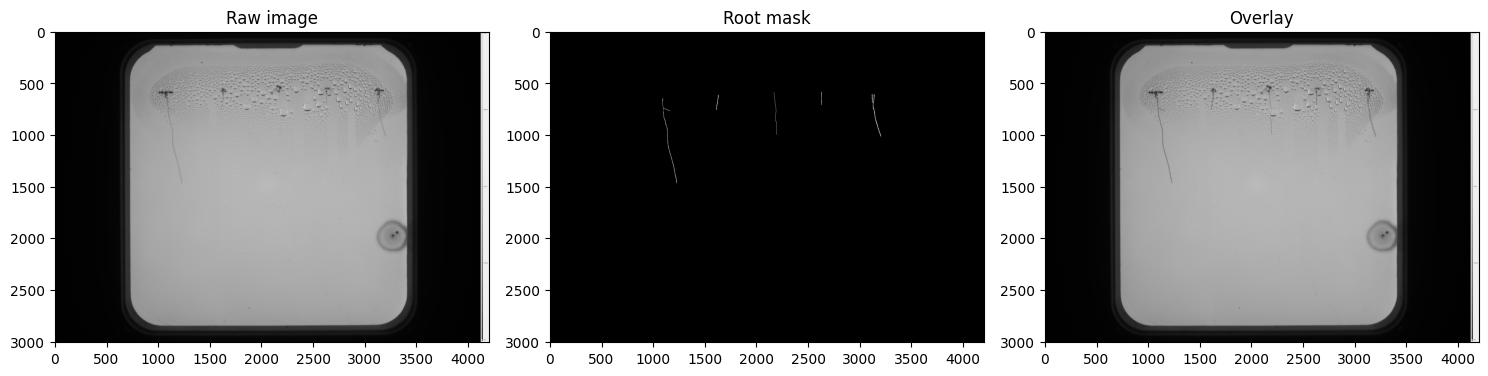

In [18]:
show_random_pair(manifest, "train")

Sample: val_uther_243263_im1
Image shape: (3006, 4202)
Mask shape: (3006, 4202)
Mask unique values: [0 1]


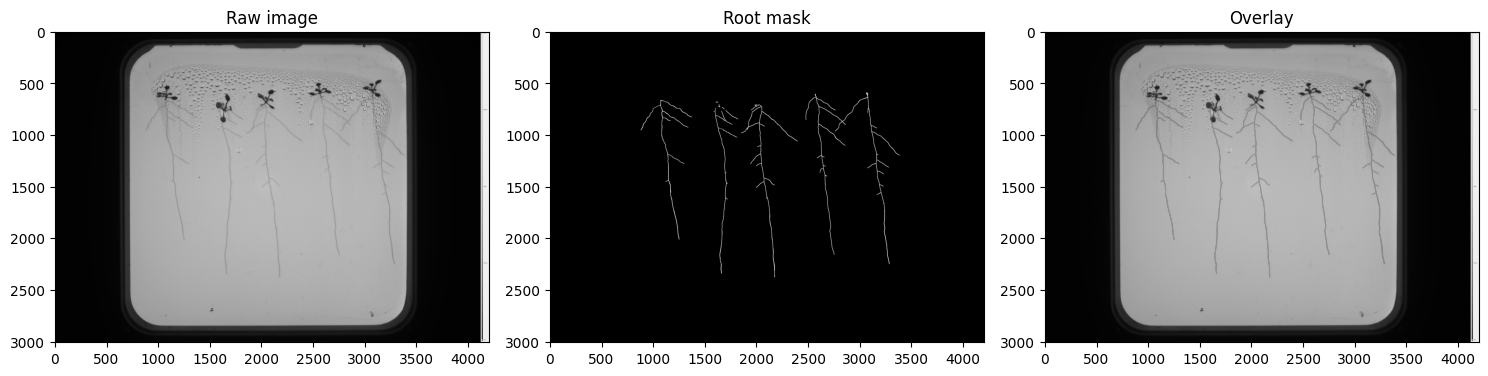

In [14]:
show_random_pair(manifest, "val")

In [19]:
from collections import defaultdict
from pathlib import Path

def audit_duplicate_ids(zip_path, kind):
    names = list_zip_files(zip_path)

    groups = defaultdict(list)

    for name in names:
        if kind == "image":
            key = image_key(name)

        elif kind == "root":
            key = root_key(name)
            if key is None:
                continue

        groups[key].append(name)

    duplicates = {
        key: files
        for key, files in groups.items()
        if len(files) > 1
    }

    return duplicates


checks = {
    "train images": audit_duplicate_ids(ZIPS["train_images"], "image"),
    "train root masks": audit_duplicate_ids(ZIPS["train_masks"], "root"),
    "val images": audit_duplicate_ids(ZIPS["val_images"], "image"),
    "val root masks": audit_duplicate_ids(ZIPS["val_masks"], "root"),
}

for name, duplicates in checks.items():
    print(f"{name}: {len(duplicates)} duplicate-ID groups")

    for key, files in list(duplicates.items())[:5]:
        print(" ", key)
        for f in files:
            print("    ", f)

train images: 0 duplicate-ID groups
train root masks: 0 duplicate-ID groups
val images: 0 duplicate-ID groups
val root masks: 0 duplicate-ID groups


In [23]:
import hashlib
import cv2
import numpy as np

def pixel_hash_from_zip(zip_path, member_name):
    with zipfile.ZipFile(zip_path, "r") as z:
        raw = z.read(member_name)

    arr = np.frombuffer(raw, np.uint8)
    image = cv2.imdecode(arr, cv2.IMREAD_UNCHANGED)

    if image is None:
        raise ValueError(f"Could not decode: {member_name}")

    image = np.ascontiguousarray(image)

    h = hashlib.sha256()
    h.update(str(image.shape).encode())
    h.update(str(image.dtype).encode())
    h.update(image.tobytes())

    return h.hexdigest()


audit_manifest = manifest.copy()

image_hashes = []
mask_hashes = []

for i, row in audit_manifest.iterrows():

    print(
        f"\rHashing {i + 1}/{len(audit_manifest)}",
        end=""
    )

    image_hashes.append(
        pixel_hash_from_zip(
            row["image_zip"],
            row["image_member"]
        )
    )

    mask_hashes.append(
        pixel_hash_from_zip(
            row["mask_zip"],
            row["mask_member"]
        )
    )

print("\nDone.")

audit_manifest["image_hash"] = image_hashes
audit_manifest["mask_hash"] = mask_hashes

Hashing 106/377

[ WARN:0@181.974] global grfmt_tiff.cpp:123 TIFF_Warning TIFFReadDirectory: Unknown field with tag 50838 (0xc696) encountered
[ WARN:0@181.974] global grfmt_tiff.cpp:123 TIFF_Warning TIFFReadDirectory: Unknown field with tag 50839 (0xc697) encountered


Hashing 107/377

[ WARN:0@182.289] global grfmt_tiff.cpp:123 TIFF_Warning TIFFReadDirectory: Unknown field with tag 50838 (0xc696) encountered
[ WARN:0@182.289] global grfmt_tiff.cpp:123 TIFF_Warning TIFFReadDirectory: Unknown field with tag 50839 (0xc697) encountered


Hashing 108/377

[ WARN:0@182.606] global grfmt_tiff.cpp:123 TIFF_Warning TIFFReadDirectory: Unknown field with tag 50838 (0xc696) encountered
[ WARN:0@182.606] global grfmt_tiff.cpp:123 TIFF_Warning TIFFReadDirectory: Unknown field with tag 50839 (0xc697) encountered


... (29 outputs left out)

[ WARN:0@247.291] global grfmt_tiff.cpp:123 TIFF_Warning TIFFReadDirectory: Unknown field with tag 50838 (0xc696) encountered
[ WARN:0@247.291] global grfmt_tiff.cpp:123 TIFF_Warning TIFFReadDirectory: Unknown field with tag 50839 (0xc697) encountered


Hashing 373/377

[ WARN:0@257.234] global grfmt_tiff.cpp:123 TIFF_Warning TIFFReadDirectory: Unknown field with tag 50838 (0xc696) encountered
[ WARN:0@257.234] global grfmt_tiff.cpp:123 TIFF_Warning TIFFReadDirectory: Unknown field with tag 50839 (0xc697) encountered


Hashing 377/377
Done.


In [24]:
duplicate_groups = []

for image_hash, group in audit_manifest.groupby("image_hash"):

    if len(group) > 1:

        duplicate_groups.append({
            "image_hash": image_hash,
            "count": len(group),
            "splits": list(group["split"]),
            "sample_ids": list(group["sample_id"]),
            "mask_hashes": list(group["mask_hash"]),
            "same_masks": group["mask_hash"].nunique() == 1,
            "cross_split": group["split"].nunique() > 1,
        })


duplicate_df = pd.DataFrame(duplicate_groups)

print("Duplicate image groups:", len(duplicate_df))

if len(duplicate_df):

    print(
        "Exact duplicate image + mask groups:",
        duplicate_df["same_masks"].sum()
    )

    print(
        "Same image but conflicting masks:",
        (~duplicate_df["same_masks"]).sum()
    )

    print(
        "Duplicate images crossing train/val:",
        duplicate_df["cross_split"].sum()
    )

    display(duplicate_df)

else:
    print("✅ No pixel-identical duplicate images found.")

Duplicate image groups: 0
✅ No pixel-identical duplicate images found.


In [25]:
from pathlib import Path
import zipfile
import shutil

CLEAN_ROOT = BASE / "task4_clean_raw"

folders = {
    "train_images": CLEAN_ROOT / "train_images",
    "train_masks": CLEAN_ROOT / "train_masks",
    "val_images": CLEAN_ROOT / "val_images",
    "val_masks": CLEAN_ROOT / "val_masks",
}

# Safety check: do not mix with old extraction results
if CLEAN_ROOT.exists():

    existing_files = [
        p for p in CLEAN_ROOT.rglob("*")
        if p.is_file()
    ]

    if existing_files:
        raise RuntimeError(
            f"{CLEAN_ROOT} already contains files. "
            "Remove or rename it before running extraction again."
        )

for folder in folders.values():
    folder.mkdir(parents=True, exist_ok=True)

print("Clean extraction folders ready.")

RuntimeError: /home/y2a/task4_clean_raw already contains files. Remove or rename it before running extraction again.

In [26]:
def extract_member(zip_path, member_name, destination):

    with zipfile.ZipFile(zip_path, "r") as z:

        data = z.read(member_name)

    destination.write_bytes(data)


for i, row in manifest.iterrows():

    split = row["split"]

    if split == "train":
        image_folder = folders["train_images"]
        mask_folder = folders["train_masks"]

    elif split == "val":
        image_folder = folders["val_images"]
        mask_folder = folders["val_masks"]

    else:
        raise ValueError(f"Unexpected split: {split}")

    image_name = Path(row["image_member"]).name
    mask_name = Path(row["mask_member"]).name

    image_destination = image_folder / image_name
    mask_destination = mask_folder / mask_name

    if image_destination.exists():
        raise RuntimeError(
            f"Duplicate output image filename: {image_name}"
        )

    if mask_destination.exists():
        raise RuntimeError(
            f"Duplicate output mask filename: {mask_name}"
        )

    extract_member(
        row["image_zip"],
        row["image_member"],
        image_destination
    )

    extract_member(
        row["mask_zip"],
        row["mask_member"],
        mask_destination
    )

    print(
        f"\rExtracting pair {i + 1}/{len(manifest)}",
        end=""
    )

print("\n✅ Clean extraction complete.")

RuntimeError: Duplicate output image filename: train_Alican_212231_im1.png

In [27]:
def count_files(folder):
    return len([
        p for p in folder.iterdir()
        if p.is_file()
    ])


train_image_count = count_files(folders["train_images"])
train_mask_count = count_files(folders["train_masks"])

val_image_count = count_files(folders["val_images"])
val_mask_count = count_files(folders["val_masks"])


print("TRAIN")
print("Images:", train_image_count)
print("Masks: ", train_mask_count)

print("\nVALIDATION")
print("Images:", val_image_count)
print("Masks: ", val_mask_count)


assert train_image_count == 314
assert train_mask_count == 314

assert val_image_count == 63
assert val_mask_count == 63

print("\n✅ Counts are exactly correct.")

TRAIN
Images: 314
Masks:  314

VALIDATION
Images: 63
Masks:  63

✅ Counts are exactly correct.


In [28]:
def check_extracted_pairs(image_folder, mask_folder):

    image_ids = {
        p.stem.lower()
        for p in image_folder.iterdir()
        if p.is_file()
    }

    mask_ids = {
        p.stem.lower().replace("_root_mask", "")
        for p in mask_folder.iterdir()
        if p.is_file()
        and p.stem.lower().endswith("_root_mask")
    }

    missing_masks = image_ids - mask_ids
    missing_images = mask_ids - image_ids

    return missing_masks, missing_images


for split in ["train", "val"]:

    missing_masks, missing_images = check_extracted_pairs(
        folders[f"{split}_images"],
        folders[f"{split}_masks"]
    )

    print(f"\n{split.upper()}")
    print("Images without masks:", len(missing_masks))
    print("Masks without images:", len(missing_images))

    assert len(missing_masks) == 0
    assert len(missing_images) == 0

print("\n✅ Every extracted image has exactly one root mask.")


TRAIN
Images without masks: 0
Masks without images: 0

VAL
Images without masks: 0
Masks without images: 0

✅ Every extracted image has exactly one root mask.


In [29]:
import random
import cv2
import numpy as np
import matplotlib.pyplot as plt


def show_random_extracted_pair(split="train"):

    image_folder = folders[f"{split}_images"]
    mask_folder = folders[f"{split}_masks"]

    image_paths = list(image_folder.iterdir())

    image_path = random.choice(image_paths)

    mask_path = (
        mask_folder /
        f"{image_path.stem}_root_mask.tif"
    )

    if not mask_path.exists():
        raise FileNotFoundError(
            f"No matching mask for {image_path.name}"
        )

    image = cv2.imread(
        str(image_path),
        cv2.IMREAD_GRAYSCALE
    )

    mask = cv2.imread(
        str(mask_path),
        cv2.IMREAD_GRAYSCALE
    )

    if image is None:
        raise ValueError(
            f"Could not read image: {image_path}"
        )

    if mask is None:
        raise ValueError(
            f"Could not read mask: {mask_path}"
        )

    print("Image:", image_path.name)
    print("Mask: ", mask_path.name)

    print("Image shape:", image.shape)
    print("Mask shape: ", mask.shape)

    print(
        "Mask unique values:",
        np.unique(mask)
    )

    assert image.shape == mask.shape

    mask_binary = mask > 0

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(15, 5)
    )

    axes[0].imshow(
        image,
        cmap="gray"
    )
    axes[0].set_title("Extracted image")

    axes[1].imshow(
        mask_binary,
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[1].set_title("Extracted root mask")

    axes[2].imshow(
        image,
        cmap="gray"
    )

    axes[2].imshow(
        np.ma.masked_where(
            ~mask_binary,
            mask_binary
        ),
        cmap="Reds",
        alpha=0.6
    )

    axes[2].set_title("Extracted pair overlay")

    plt.tight_layout()
    plt.show()

In [8]:
show_random_extracted_pair("train")

NameError: name 'folders' is not defined

Image: train_Alican_242058_im1.png
Mask:  train_Alican_242058_im1_root_mask.tif
Image shape: (3006, 4202)
Mask shape:  (3006, 4202)
Mask unique values: [0 1]


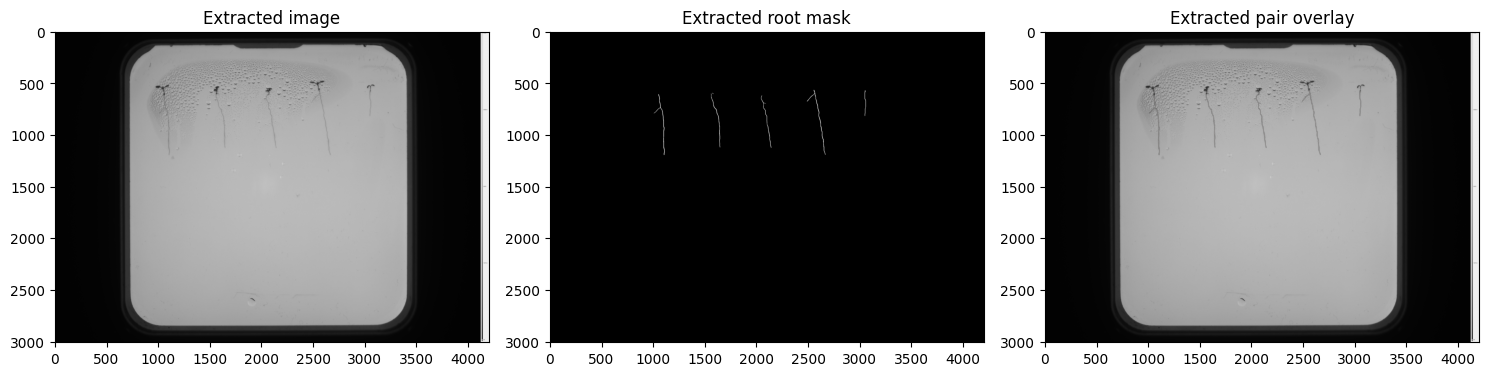

In [30]:
show_random_extracted_pair("val")

In [31]:
import cv2
import numpy as np


def largest_true_region(binary_profile):

    # Force profile into one flat boolean array
    binary_profile = np.asarray(
        binary_profile
    ).ravel().astype(bool)

    regions = []
    start = None

    for i, value in enumerate(binary_profile):

        if value and start is None:
            start = i

        elif not value and start is not None:
            regions.append((start, i - 1))
            start = None

    if start is not None:
        regions.append(
            (start, len(binary_profile) - 1)
        )

    if not regions:
        raise ValueError(
            "No bright Petri-dish region detected."
        )

    return max(
        regions,
        key=lambda r: r[1] - r[0]
    )


def detect_petri_square(image):

    if image is None:
        raise ValueError("Image could not be loaded.")

    gray = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2GRAY
    )

    h, w = gray.shape

    # Ignore extreme outer areas when measuring brightness profiles
    y1 = int(h * 0.20)
    y2 = int(h * 0.80)

    x1 = int(w * 0.20)
    x2 = int(w * 0.80)

    column_profile = np.median(
        gray[y1:y2, :],
        axis=0
    )

    row_profile = np.median(
        gray[:, x1:x2],
        axis=1
    )

    column_profile = cv2.GaussianBlur(
        column_profile.astype(np.float32).reshape(1, -1),
        (31, 1),
        0
    ).ravel()

    row_profile = cv2.GaussianBlur(
        row_profile.astype(np.float32).reshape(-1, 1),
        (1, 31),
        0
    ).ravel()

    column_uint8 = np.clip(
        column_profile,
        0,
        255
    ).astype(np.uint8)

    row_uint8 = np.clip(
        row_profile,
        0,
        255
    ).astype(np.uint8)

    _, column_binary = cv2.threshold(
        column_uint8,
        0,
        255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    _, row_binary = cv2.threshold(
        row_uint8,
        0,
        255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    left, right = largest_true_region(
        column_binary > 0
    )

    top, bottom = largest_true_region(
        row_binary > 0
    )

    detected_width = right - left + 1
    detected_height = bottom - top + 1

    # Task 2 uses a square dish crop
    side = int(round(
        (detected_width + detected_height) / 2
    ))

    center_x = (left + right) / 2
    center_y = (top + bottom) / 2

    left = int(round(
        center_x - (side - 1) / 2
    ))

    top = int(round(
        center_y - (side - 1) / 2
    ))

    right = left + side
    bottom = top + side

    # Keep crop inside image
    if left < 0:
        right -= left
        left = 0

    if top < 0:
        bottom -= top
        top = 0

    if right > w:
        shift = right - w
        left -= shift
        right = w

    if bottom > h:
        shift = bottom - h
        top -= shift
        bottom = h

    return {
        "left": int(left),
        "top": int(top),
        "right": int(right),
        "bottom": int(bottom)
    }

In [32]:
import random
import matplotlib.pyplot as plt
from pathlib import Path


def check_random_petri_crop(split="train"):

    image_folder = folders[f"{split}_images"]
    mask_folder = folders[f"{split}_masks"]

    image_path = random.choice(
        list(image_folder.iterdir())
    )

    mask_path = (
        mask_folder /
        f"{image_path.stem}_root_mask.tif"
    )

    image = cv2.imread(
        str(image_path),
        cv2.IMREAD_COLOR
    )

    mask = cv2.imread(
        str(mask_path),
        cv2.IMREAD_GRAYSCALE
    )

    if image is None or mask is None:
        raise ValueError("Could not load image or mask.")

    if image.shape[:2] != mask.shape:
        raise ValueError("Image and mask dimensions do not match.")

    edges = detect_petri_square(image)

    left = edges["left"]
    top = edges["top"]
    right = edges["right"]
    bottom = edges["bottom"]

    image_crop = image[
        top:bottom,
        left:right
    ]

    mask_crop = mask[
        top:bottom,
        left:right
    ]

    original_root_pixels = np.count_nonzero(mask)
    cropped_root_pixels = np.count_nonzero(mask_crop)

    root_retention = (
        cropped_root_pixels /
        original_root_pixels * 100
        if original_root_pixels > 0
        else 100
    )

    marked = image.copy()

    cv2.rectangle(
        marked,
        (left, top),
        (right - 1, bottom - 1),
        (0, 255, 0),
        8
    )

    print("Sample:", image_path.name)
    print("Original image:", image.shape)
    print("Original mask: ", mask.shape)
    print("Crop edges:", edges)
    print("Cropped image:", image_crop.shape)
    print("Cropped mask: ", mask_crop.shape)
    print(
        f"Root pixels retained: {root_retention:.4f}%"
    )

    assert image_crop.shape[:2] == mask_crop.shape
    assert image_crop.shape[0] == image_crop.shape[1]

    mask_binary = mask_crop > 0

    fig, axes = plt.subplots(
        1,
        4,
        figsize=(20, 5)
    )

    axes[0].imshow(
        cv2.cvtColor(marked, cv2.COLOR_BGR2RGB)
    )
    axes[0].set_title("Detected dish")

    axes[1].imshow(
        cv2.cvtColor(image_crop, cv2.COLOR_BGR2RGB)
    )
    axes[1].set_title("Petri crop")

    axes[2].imshow(
        mask_crop,
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[2].set_title("Cropped root mask")

    axes[3].imshow(
        cv2.cvtColor(image_crop, cv2.COLOR_BGR2RGB)
    )

    axes[3].imshow(
        np.ma.masked_where(
            ~mask_binary,
            mask_binary
        ),
        cmap="Reds",
        alpha=0.6
    )

    axes[3].set_title("Crop + root overlay")

    plt.tight_layout()
    plt.show()

Sample: train_Karna_231146_im5.png
Original image: (3006, 4112, 3)
Original mask:  (3006, 4112)
Crop edges: {'left': 789, 'top': 86, 'right': 3505, 'bottom': 2802}
Cropped image: (2716, 2716, 3)
Cropped mask:  (2716, 2716)
Root pixels retained: 100.0000%


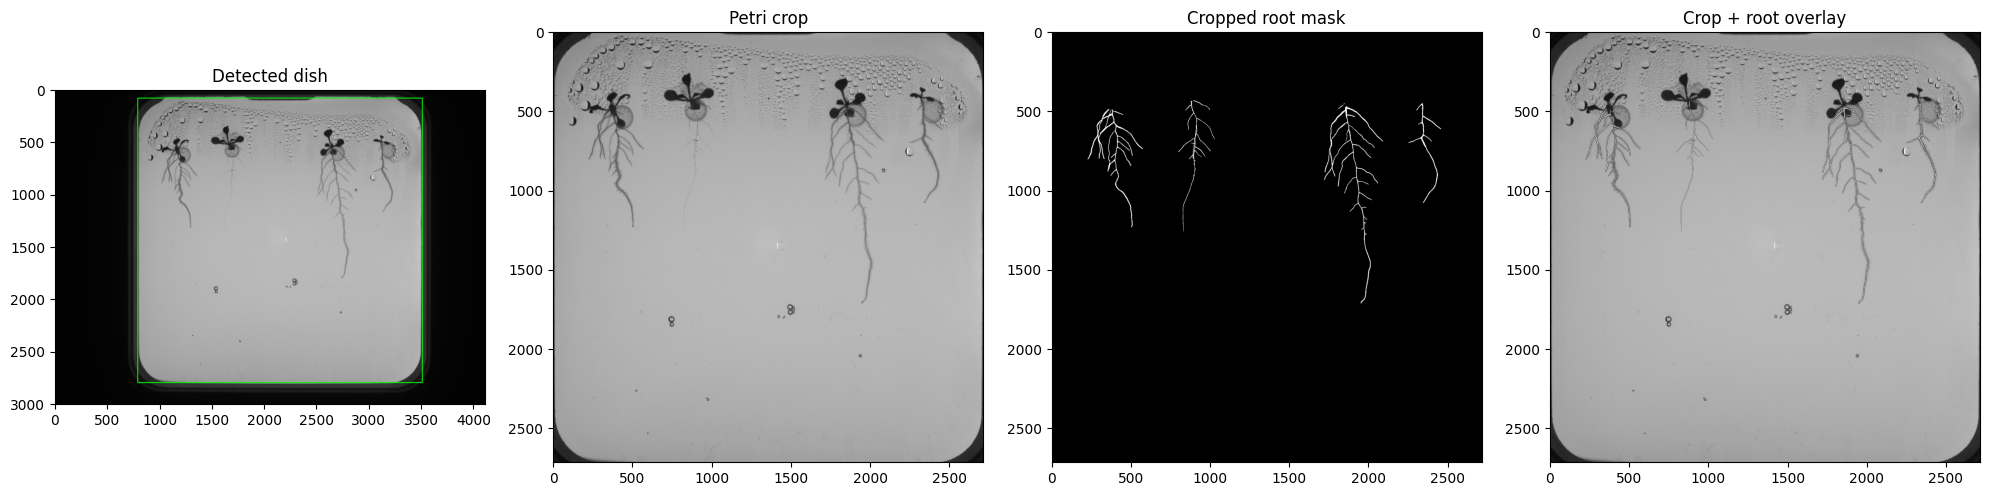

In [33]:
check_random_petri_crop("train")

Sample: val_Karna_243756_im1.png
Original image: (3006, 4202, 3)
Original mask:  (3006, 4202)
Crop edges: {'left': 788, 'top': 88, 'right': 3504, 'bottom': 2804}
Cropped image: (2716, 2716, 3)
Cropped mask:  (2716, 2716)
Root pixels retained: 100.0000%


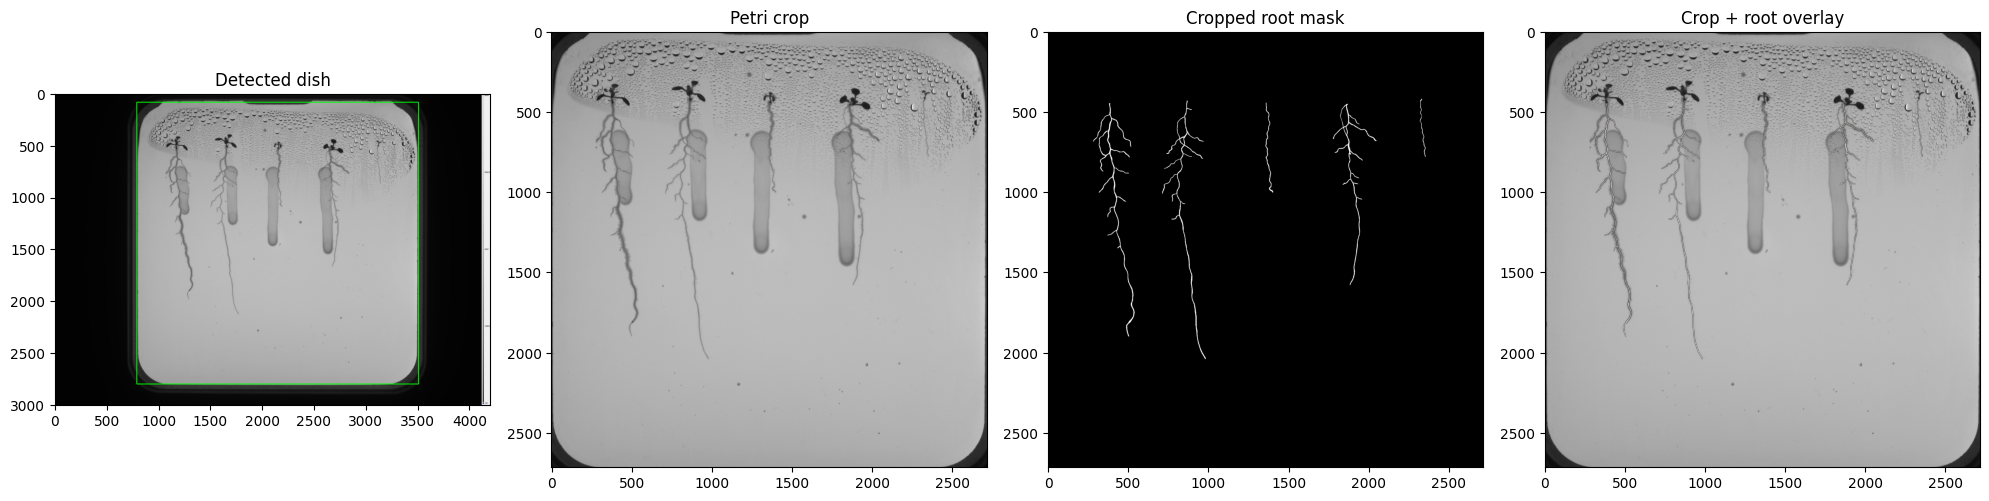

In [34]:
check_random_petri_crop("val")

SyntaxError: expected 'except' or 'finally' block (1712444889.py, line 58)

In [36]:
failed = petri_audit[
    petri_audit["status"] != "OK"
]

successful = petri_audit[
    petri_audit["status"] == "OK"
]

low_retention = successful[
    successful["root_retention_percent"] < 99.9
]

non_square = successful[
    successful["square_crop"] == False
]

misaligned = successful[
    successful["aligned"] == False
]


print("TOTAL:", len(petri_audit))
print("Successful:", len(successful))
print("Failed:", len(failed))

print(
    "Root retention < 99.9%:",
    len(low_retention)
)

print(
    "Non-square crops:",
    len(non_square)
)

print(
    "Image/mask crop mismatches:",
    len(misaligned)
)

print("\nCROP SIZE")
print(
    successful["crop_height"].describe()
)

print("\nROOT RETENTION")
print(
    successful[
        "root_retention_percent"
    ].describe()
)

TOTAL: 377
Successful: 377
Failed: 0
Root retention < 99.9%: 18
Non-square crops: 0
Image/mask crop mismatches: 0

CROP SIZE
count     377.000000
mean     2708.098143
std        10.460586
min      2680.000000
25%      2695.000000
50%      2716.000000
75%      2716.000000
max      2717.000000
Name: crop_height, dtype: float64

ROOT RETENTION
count    377.000000
mean      99.976393
std        0.164025
min       97.859636
25%      100.000000
50%      100.000000
75%      100.000000
max      100.000000
Name: root_retention_percent, dtype: float64


In [37]:
petri_audit.to_csv(
    "task4_petri_audit.csv",
    index=False
)

print("Saved task4_petri_audit.csv")

Saved task4_petri_audit.csv


In [37]:
worst = (
    successful
    .sort_values("root_retention_percent")
    .iloc[0]
)

print("Worst sample:")
print(worst["sample_id"])

print(
    "Root retention:",
    worst["root_retention_percent"]
)

NameError: name 'successful' is not defined

In [38]:
def show_specific_petri_crop(sample_id, split):

    image_path = (
        folders[f"{split}_images"] /
        f"{sample_id}.png"
    )

    if not image_path.exists():

        candidates = list(
            folders[f"{split}_images"].glob(
                f"{sample_id}.*"
            )
        )

        if not candidates:
            raise FileNotFoundError(sample_id)

        image_path = candidates[0]

    mask_path = (
        folders[f"{split}_masks"] /
        f"{sample_id}_root_mask.tif"
    )

    image = cv2.imread(
        str(image_path),
        cv2.IMREAD_COLOR
    )

    mask = cv2.imread(
        str(mask_path),
        cv2.IMREAD_GRAYSCALE
    )

    edges = detect_petri_square(image)

    l = edges["left"]
    t = edges["top"]
    r = edges["right"]
    b = edges["bottom"]

    crop = image[t:b, l:r]
    mask_crop = mask[t:b, l:r]

    marked = image.copy()

    cv2.rectangle(
        marked,
        (l, t),
        (r - 1, b - 1),
        (0, 255, 0),
        8
    )

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(17, 5)
    )

    axes[0].imshow(
        cv2.cvtColor(
            marked,
            cv2.COLOR_BGR2RGB
        )
    )

    axes[0].set_title(
        "Detected crop"
    )

    axes[1].imshow(
        cv2.cvtColor(
            crop,
            cv2.COLOR_BGR2RGB
        )
    )

    axes[1].set_title(
        "Cropped Petri dish"
    )

    axes[2].imshow(
        cv2.cvtColor(
            crop,
            cv2.COLOR_BGR2RGB
        )
    )

    root = mask_crop > 0

    axes[2].imshow(
        np.ma.masked_where(
            ~root,
            root
        ),
        cmap="Reds",
        alpha=0.6
    )

    axes[2].set_title(
        "Cropped root overlay"
    )

    plt.tight_layout()
    plt.show()

In [39]:
def inspect_root_loss(sample_id, split):

    image_folder = folders[f"{split}_images"]
    mask_folder = folders[f"{split}_masks"]

    sample_lower = sample_id.lower()

    image_candidates = [
        p for p in image_folder.iterdir()
        if p.is_file()
        and p.stem.lower() == sample_lower
    ]

    if len(image_candidates) != 1:
        raise ValueError(
            f"Expected exactly 1 image for {sample_id}, "
            f"found {len(image_candidates)}"
        )

    image_path = image_candidates[0]

    mask_candidates = [
        p for p in mask_folder.iterdir()
        if p.is_file()
        and p.stem.lower()
        == f"{sample_lower}_root_mask"
    ]

    if len(mask_candidates) != 1:
        raise ValueError(
            f"Expected exactly 1 root mask for {sample_id}, "
            f"found {len(mask_candidates)}"
        )

    mask_path = mask_candidates[0]

    image = cv2.imread(
        str(image_path),
        cv2.IMREAD_COLOR
    )

    mask = cv2.imread(
        str(mask_path),
        cv2.IMREAD_GRAYSCALE
    )

    edges = detect_petri_square(image)

    l = edges["left"]
    t = edges["top"]
    r = edges["right"]
    b = edges["bottom"]

    root = mask > 0

    inside_crop = np.zeros(
        root.shape,
        dtype=bool
    )

    inside_crop[t:b, l:r] = True

    lost_root = root & ~inside_crop

    total_root_pixels = np.count_nonzero(root)
    lost_root_pixels = np.count_nonzero(lost_root)

    retained = (
        100 *
        (total_root_pixels - lost_root_pixels) /
        total_root_pixels
    )

    print("Image:", image_path.name)
    print("Mask:", mask_path.name)
    print("Total root pixels:", total_root_pixels)
    print("Lost root pixels:", lost_root_pixels)
    print(f"Root retention: {retained:.4f}%")

    rgb = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(20, 6)
    )

    axes[0].imshow(rgb)

    rectangle = plt.Rectangle(
        (l, t),
        r - l,
        b - t,
        fill=False,
        linewidth=3
    )

    axes[0].add_patch(rectangle)
    axes[0].set_title("Petri crop boundary")

    axes[1].imshow(rgb)
    axes[1].imshow(
        np.ma.masked_where(~root, root),
        cmap="Reds",
        alpha=0.65
    )
    axes[1].set_title("All labelled root pixels")

    axes[2].imshow(rgb)
    axes[2].imshow(
        np.ma.masked_where(
            ~lost_root,
            lost_root
        ),
        cmap="Reds",
        alpha=0.9
    )
    axes[2].set_title("Root pixels lost by crop")

    plt.tight_layout()
    plt.show()

In [40]:
for split in ["train", "val"]:
    matches = [
        p.name
        for p in folders[f"{split}_images"].iterdir()
        if "245486" in p.name.lower()
    ]

    print(split, matches)

train []
val ['train_Dean_245486_im1.png']


Image: train_Dean_245486_im1.png
Mask: train_Dean_245486_im1_root_mask.tif
Total root pixels: 21772
Lost root pixels: 466
Root retention: 97.8596%


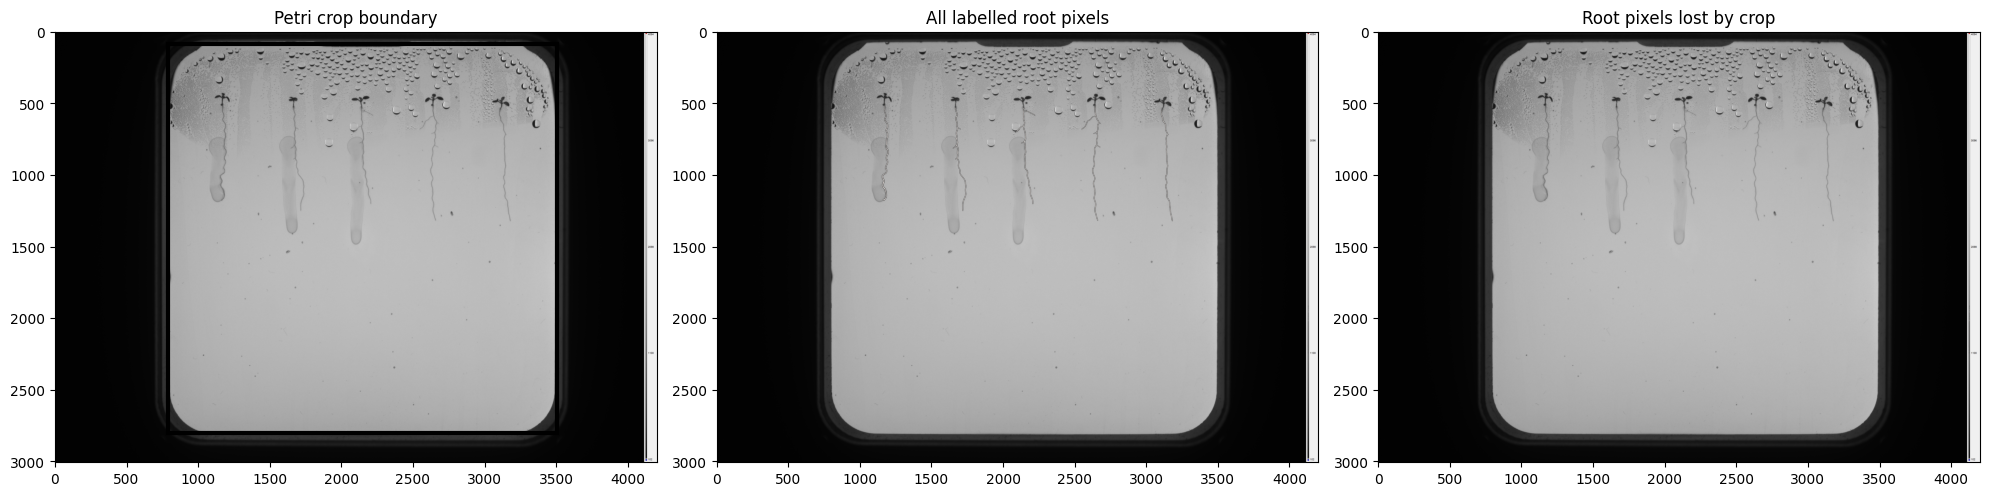

In [41]:
inspect_root_loss(
    "train_Dean_245486_im1",
    "val"
)

In [42]:
def add_square_margin(edges, image_shape, margin=20):

    h, w = image_shape[:2]

    left = edges["left"]
    top = edges["top"]
    right = edges["right"]
    bottom = edges["bottom"]

    current_side = right - left

    # Enlarge equally in every direction
    new_side = current_side + (2 * margin)

    # Cannot exceed image dimensions
    new_side = min(new_side, h, w)

    center_x = (left + right) / 2
    center_y = (top + bottom) / 2

    new_left = int(round(center_x - new_side / 2))
    new_top = int(round(center_y - new_side / 2))

    new_right = new_left + new_side
    new_bottom = new_top + new_side

    # Shift the square if it crosses an image boundary
    if new_left < 0:
        new_right -= new_left
        new_left = 0

    if new_top < 0:
        new_bottom -= new_top
        new_top = 0

    if new_right > w:
        shift = new_right - w
        new_left -= shift
        new_right = w

    if new_bottom > h:
        shift = new_bottom - h
        new_top -= shift
        new_bottom = h

    return {
        "left": int(new_left),
        "top": int(new_top),
        "right": int(new_right),
        "bottom": int(new_bottom)
    }

In [43]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import random


def largest_true_region(binary_profile):

    binary_profile = np.asarray(
        binary_profile
    ).ravel().astype(bool)

    regions = []
    start = None

    for i, value in enumerate(binary_profile):

        if value and start is None:
            start = i

        elif not value and start is not None:
            regions.append((start, i - 1))
            start = None

    if start is not None:
        regions.append(
            (start, len(binary_profile) - 1)
        )

    if not regions:
        raise ValueError(
            "No bright Petri-dish region detected."
        )

    return max(
        regions,
        key=lambda r: r[1] - r[0]
    )


def detect_petri_square(image):

    if image is None:
        raise ValueError("Image could not be loaded.")

    gray = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2GRAY
    )

    h, w = gray.shape

    y1 = int(h * 0.20)
    y2 = int(h * 0.80)

    x1 = int(w * 0.20)
    x2 = int(w * 0.80)

    column_profile = np.median(
        gray[y1:y2, :],
        axis=0
    )

    row_profile = np.median(
        gray[:, x1:x2],
        axis=1
    )

    column_profile = cv2.GaussianBlur(
        column_profile.astype(np.float32).reshape(1, -1),
        (31, 1),
        0
    ).ravel()

    row_profile = cv2.GaussianBlur(
        row_profile.astype(np.float32).reshape(-1, 1),
        (1, 31),
        0
    ).ravel()

    column_uint8 = np.clip(
        column_profile,
        0,
        255
    ).astype(np.uint8)

    row_uint8 = np.clip(
        row_profile,
        0,
        255
    ).astype(np.uint8)

    _, column_binary = cv2.threshold(
        column_uint8,
        0,
        255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    _, row_binary = cv2.threshold(
        row_uint8,
        0,
        255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    left, right = largest_true_region(
        column_binary > 0
    )

    top, bottom = largest_true_region(
        row_binary > 0
    )

    detected_width = right - left + 1
    detected_height = bottom - top + 1

    side = int(round(
        (detected_width + detected_height) / 2
    ))

    center_x = (left + right) / 2
    center_y = (top + bottom) / 2

    left = int(round(
        center_x - side / 2
    ))

    top = int(round(
        center_y - side / 2
    ))

    side = min(side, h, w)

    left = max(
        0,
        min(left, w - side)
    )

    top = max(
        0,
        min(top, h - side)
    )

    right = left + side
    bottom = top + side

    return {
        "left": int(left),
        "top": int(top),
        "right": int(right),
        "bottom": int(bottom)
    }


def add_square_margin(edges, image_shape, margin=20):

    h, w = image_shape[:2]

    side = edges["right"] - edges["left"]

    new_side = min(
        side + (2 * margin),
        h,
        w
    )

    center_x = (
        edges["left"] +
        edges["right"]
    ) / 2

    center_y = (
        edges["top"] +
        edges["bottom"]
    ) / 2

    left = int(round(
        center_x - new_side / 2
    ))

    top = int(round(
        center_y - new_side / 2
    ))

    # Shift square inside image without changing its size
    left = max(
        0,
        min(left, w - new_side)
    )

    top = max(
        0,
        min(top, h - new_side)
    )

    right = left + new_side
    bottom = top + new_side

    return {
        "left": int(left),
        "top": int(top),
        "right": int(right),
        "bottom": int(bottom)
    }


def get_petri_edges(image, margin=20):

    edges = detect_petri_square(image)

    edges = add_square_margin(
        edges,
        image.shape,
        margin=margin
    )

    return edges

In [44]:
def find_pair(sample_id, split):

    image_folder = folders[f"{split}_images"]
    mask_folder = folders[f"{split}_masks"]

    target = sample_id.lower()

    images = [
        p for p in image_folder.iterdir()
        if p.is_file()
        and p.stem.lower() == target
    ]

    masks = [
        p for p in mask_folder.iterdir()
        if p.is_file()
        and p.stem.lower()
        == f"{target}_root_mask"
    ]

    if len(images) != 1:
        raise ValueError(
            f"{sample_id}: found {len(images)} images."
        )

    if len(masks) != 1:
        raise ValueError(
            f"{sample_id}: found {len(masks)} root masks."
        )

    return images[0], masks[0]

In [46]:
def check_random_petri_crop(split="train"):

    image_folder = folders[f"{split}_images"]

    image_paths = [
        p for p in image_folder.iterdir()
        if p.is_file()
    ]

    image_path = random.choice(image_paths)

    image_path, mask_path = find_pair(
        image_path.stem,
        split
    )

    image = cv2.imread(
        str(image_path),
        cv2.IMREAD_COLOR
    )

    mask = cv2.imread(
        str(mask_path),
        cv2.IMREAD_GRAYSCALE
    )

    if image is None or mask is None:
        raise ValueError("Could not load image or mask.")

    if image.shape[:2] != mask.shape:
        raise ValueError(
            "Image and mask dimensions differ."
        )

    edges = get_petri_edges(
        image,
        margin=20
    )

    l = edges["left"]
    t = edges["top"]
    r = edges["right"]
    b = edges["bottom"]

    image_crop = image[t:b, l:r]
    mask_crop = mask[t:b, l:r]

    total_root = np.count_nonzero(mask)
    retained_root = np.count_nonzero(mask_crop)

    retention = (
        retained_root / total_root * 100
        if total_root > 0
        else 100.0
    )

    print("Sample:", image_path.stem)
    print("Split:", split)
    print("Original shape:", image.shape)
    print("Crop shape:", image_crop.shape)
    print("Mask shape:", mask_crop.shape)
    print("Crop edges:", edges)
    print(f"Root retention: {retention:.4f}%")

    assert image_crop.shape[:2] == mask_crop.shape
    assert image_crop.shape[0] == image_crop.shape[1]

    marked = image.copy()

    cv2.rectangle(
        marked,
        (l, t),
        (r - 1, b - 1),
        (0, 255, 0),
        8
    )

    root = mask_crop > 0

    fig, axes = plt.subplots(
        1,
        4,
        figsize=(20, 5)
    )

    axes[0].imshow(
        cv2.cvtColor(
            marked,
            cv2.COLOR_BGR2RGB
        )
    )
    axes[0].set_title("Detected Petri crop")

    axes[1].imshow(
        cv2.cvtColor(
            image_crop,
            cv2.COLOR_BGR2RGB
        )
    )
    axes[1].set_title("Cropped image")

    axes[2].imshow(
        mask_crop,
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[2].set_title("Cropped root mask")

    axes[3].imshow(
        cv2.cvtColor(
            image_crop,
            cv2.COLOR_BGR2RGB
        )
    )

    axes[3].imshow(
        np.ma.masked_where(
            ~root,
            root
        ),
        cmap="Reds",
        alpha=0.6
    )

    axes[3].set_title("Root overlay")

    plt.tight_layout()
    plt.show()

Sample: train_Karna_232567_im3
Split: train
Original shape: (3006, 4112, 3)
Crop shape: (2756, 2756, 3)
Mask shape: (2756, 2756)
Crop edges: {'left': 768, 'top': 66, 'right': 3524, 'bottom': 2822}
Root retention: 100.0000%


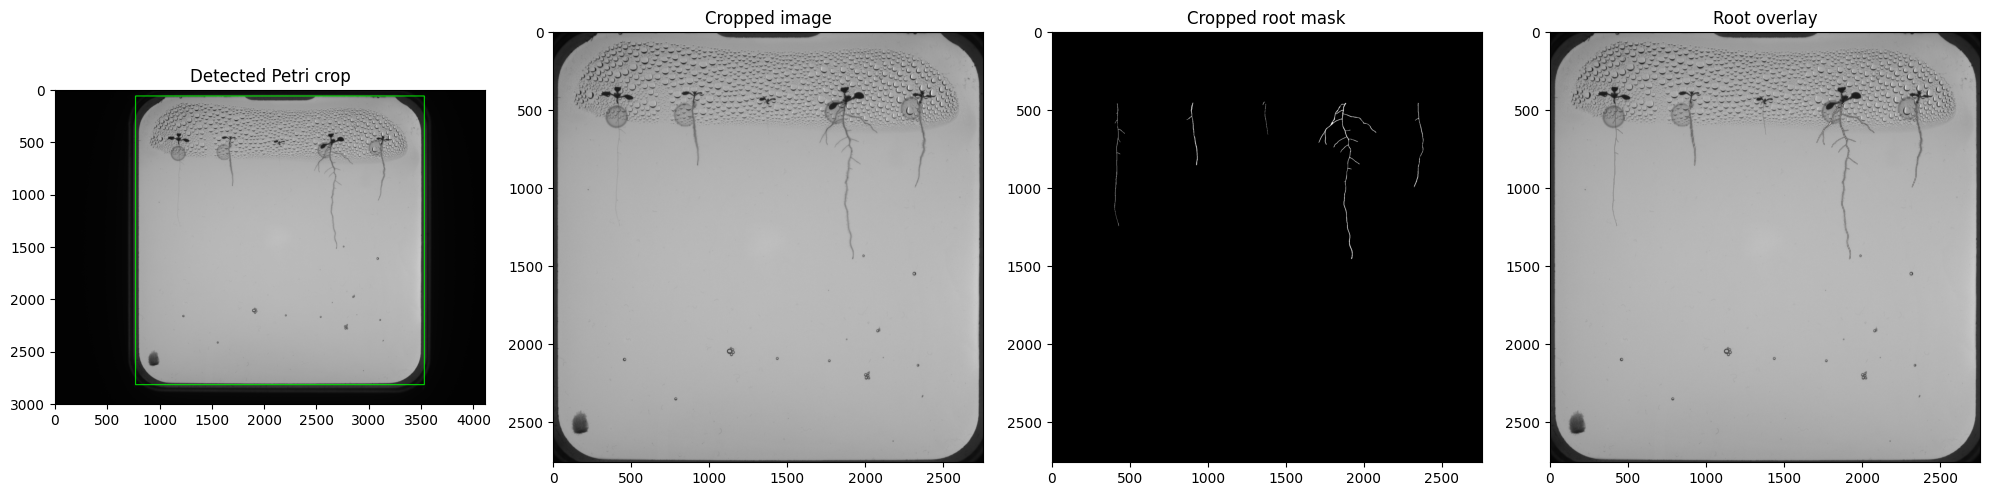

In [47]:
check_random_petri_crop("train")

In [50]:
audit_rows = []

for split in ["train", "val"]:

    image_folder = folders[f"{split}_images"]

    image_paths = sorted([
        p for p in image_folder.iterdir()
        if p.is_file()
    ])

    for i, image_path in enumerate(image_paths):

        result = {
            "split": split,
            "sample_id": image_path.stem,
            "status": "OK",
            "error": ""
        }

        try:

            image_path, mask_path = find_pair(
                image_path.stem,
                split
            )

            image = cv2.imread(
                str(image_path),
                cv2.IMREAD_COLOR
            )

            mask = cv2.imread(
                str(mask_path),
                cv2.IMREAD_GRAYSCALE
            )

            if image is None or mask is None:
                raise ValueError("Could not load image or mask.")

            if image.shape[:2] != mask.shape:
                raise ValueError("Image/mask dimensions differ.")

            edges = get_petri_edges(
                image,
                margin=20
            )

            l = edges["left"]
            t = edges["top"]
            r = edges["right"]
            b = edges["bottom"]

            image_crop = image[t:b, l:r]
            mask_crop = mask[t:b, l:r]

            total_root = np.count_nonzero(mask)
            retained_root = np.count_nonzero(mask_crop)

            retention = (
                retained_root / total_root * 100
                if total_root > 0
                else 100.0
            )

            result.update({
                "crop_height": image_crop.shape[0],
                "crop_width": image_crop.shape[1],
                "root_retention_percent": retention,
                "square_crop":
                    image_crop.shape[0] == image_crop.shape[1],
                "aligned":
                    image_crop.shape[:2] == mask_crop.shape
            })

        except Exception as e:

            result["status"] = "FAIL"
            result["error"] = str(e)

        audit_rows.append(result)

        print(
            f"\rAuditing {split}: "
            f"{i + 1}/{len(image_paths)}",
            end=""
        )

    print()


petri_audit = pd.DataFrame(audit_rows)

successful = petri_audit[
    petri_audit["status"] == "OK"
].copy()

failed = petri_audit[
    petri_audit["status"] != "OK"
].copy()

worst = (
    successful
    .sort_values("root_retention_percent")
    .iloc[0]
)

print("\nTOTAL:", len(petri_audit))
print("Successful:", len(successful))
print("Failed:", len(failed))

print("\nWorst sample:")
print(worst["sample_id"])
print("Split:", worst["split"])
print(
    "Root retention:",
    worst["root_retention_percent"]
)

Auditing train: 105/314

[ WARN:0@582.333] global grfmt_tiff.cpp:123 TIFF_Warning TIFFReadDirectory: Unknown field with tag 50838 (0xc696) encountered
[ WARN:0@582.333] global grfmt_tiff.cpp:123 TIFF_Warning TIFFReadDirectory: Unknown field with tag 50839 (0xc697) encountered


Auditing train: 106/314

[ WARN:0@582.598] global grfmt_tiff.cpp:123 TIFF_Warning TIFFReadDirectory: Unknown field with tag 50838 (0xc696) encountered
[ WARN:0@582.598] global grfmt_tiff.cpp:123 TIFF_Warning TIFFReadDirectory: Unknown field with tag 50839 (0xc697) encountered


Auditing train: 107/314

[ WARN:0@582.837] global grfmt_tiff.cpp:123 TIFF_Warning TIFFReadDirectory: Unknown field with tag 50838 (0xc696) encountered
[ WARN:0@582.837] global grfmt_tiff.cpp:123 TIFF_Warning TIFFReadDirectory: Unknown field with tag 50839 (0xc697) encountered


... (29 outputs left out)

[ WARN:0@635.914] global grfmt_tiff.cpp:123 TIFF_Warning TIFFReadDirectory: Unknown field with tag 50838 (0xc696) encountered
[ WARN:0@635.914] global grfmt_tiff.cpp:123 TIFF_Warning TIFFReadDirectory: Unknown field with tag 50839 (0xc697) encountered


Auditing val: 58/63

[ WARN:0@644.524] global grfmt_tiff.cpp:123 TIFF_Warning TIFFReadDirectory: Unknown field with tag 50838 (0xc696) encountered
[ WARN:0@644.524] global grfmt_tiff.cpp:123 TIFF_Warning TIFFReadDirectory: Unknown field with tag 50839 (0xc697) encountered


Auditing val: 63/63

TOTAL: 377
Successful: 377
Failed: 0

Worst sample:
train_Dean_245486_im1
Split: val
Root retention: 97.85963623002021


In [51]:
successful = petri_audit[
    petri_audit["status"] == "OK"
].copy()

worst = (
    successful
    .sort_values("root_retention_percent")
    .iloc[0]
)

print("Worst sample:")
print(worst["sample_id"])
print("Split:", worst["split"])
print(
    "Root retention:",
    worst["root_retention_percent"]
)

Worst sample:
train_Dean_245486_im1
Split: val
Root retention: 97.85963623002021


In [52]:
worst = (
    successful
    .sort_values("root_retention_percent")
    .iloc[0]
)

print("Worst sample:")
print(worst["sample_id"])
print("Split:", worst["split"])
print(
    "Root retention:",
    worst["root_retention_percent"]
)

Worst sample:
train_Dean_245486_im1
Split: val
Root retention: 97.85963623002021


In [53]:
image_path, mask_path = find_pair(
    worst["sample_id"],
    worst["split"]
)

image = cv2.imread(
    str(image_path),
    cv2.IMREAD_COLOR
)

mask = cv2.imread(
    str(mask_path),
    cv2.IMREAD_GRAYSCALE
)

root = mask > 0
total_root = np.count_nonzero(root)

base_edges = detect_petri_square(image)

print("Sample:", worst["sample_id"])
print("Original image shape:", image.shape)
print("Base detected edges:", base_edges)

print("\nMARGIN TEST")
print("-" * 60)

for margin in [0, 20, 50, 100, 150, 200, 300]:

    if margin == 0:
        edges = base_edges
    else:
        edges = add_square_margin(
            base_edges,
            image.shape,
            margin=margin
        )

    l = edges["left"]
    t = edges["top"]
    r = edges["right"]
    b = edges["bottom"]

    cropped_mask = mask[t:b, l:r]

    retained = np.count_nonzero(cropped_mask)

    retention = (
        retained / total_root * 100
        if total_root > 0
        else 100
    )

    print(
        f"Margin {margin:3d}px | "
        f"crop {b-t}x{r-l} | "
        f"retention {retention:.6f}% | "
        f"lost {total_root-retained}"
    )

Sample: train_Dean_245486_im1
Original image shape: (3006, 4202, 3)
Base detected edges: {'left': 787, 'top': 88, 'right': 3503, 'bottom': 2804}

MARGIN TEST
------------------------------------------------------------
Margin   0px | crop 2716x2716 | retention 97.859636% | lost 466
Margin  20px | crop 2756x2756 | retention 97.859636% | lost 466
Margin  50px | crop 2816x2816 | retention 97.859636% | lost 466
Margin 100px | crop 2916x2916 | retention 97.859636% | lost 466
Margin 150px | crop 3006x3006 | retention 97.859636% | lost 466
Margin 200px | crop 3006x3006 | retention 97.859636% | lost 466
Margin 300px | crop 3006x3006 | retention 97.859636% | lost 466


In [54]:
for margin in [0, 20, 50, 100, 150, 200, 300]:

    if margin == 0:
        edges = base_edges
    else:
        edges = add_square_margin(
            base_edges,
            image.shape,
            margin=margin
        )

    print(
        margin,
        edges,
        "side =",
        edges["right"] - edges["left"]
    )

0 {'left': 787, 'top': 88, 'right': 3503, 'bottom': 2804} side = 2716
20 {'left': 767, 'top': 68, 'right': 3523, 'bottom': 2824} side = 2756
50 {'left': 737, 'top': 38, 'right': 3553, 'bottom': 2854} side = 2816
100 {'left': 687, 'top': 0, 'right': 3603, 'bottom': 2916} side = 2916
150 {'left': 642, 'top': 0, 'right': 3648, 'bottom': 3006} side = 3006
200 {'left': 642, 'top': 0, 'right': 3648, 'bottom': 3006} side = 3006
300 {'left': 642, 'top': 0, 'right': 3648, 'bottom': 3006} side = 3006


In [55]:
# Use the maximum possible square crop
max_edges = add_square_margin(
    base_edges,
    image.shape,
    margin=150
)

l = max_edges["left"]
t = max_edges["top"]
r = max_edges["right"]
b = max_edges["bottom"]

root = mask > 0

inside = np.zeros_like(
    root,
    dtype=bool
)

inside[t:b, l:r] = True

lost_root = root & ~inside

ys, xs = np.where(lost_root)

print("Lost root pixels:", len(xs))

if len(xs) > 0:

    print("\nLost pixel coordinate range:")
    print("x:", xs.min(), "to", xs.max())
    print("y:", ys.min(), "to", ys.max())

    print("\nLocation:")
    print("Left of crop:", np.sum(xs < l))
    print("Right of crop:", np.sum(xs >= r))
    print("Above crop:", np.sum(ys < t))
    print("Below crop:", np.sum(ys >= b))

Lost root pixels: 466

Lost pixel coordinate range:
x: 4126 to 4127
y: 1915 to 2247

Location:
Left of crop: 0
Right of crop: 466
Above crop: 0
Below crop: 0


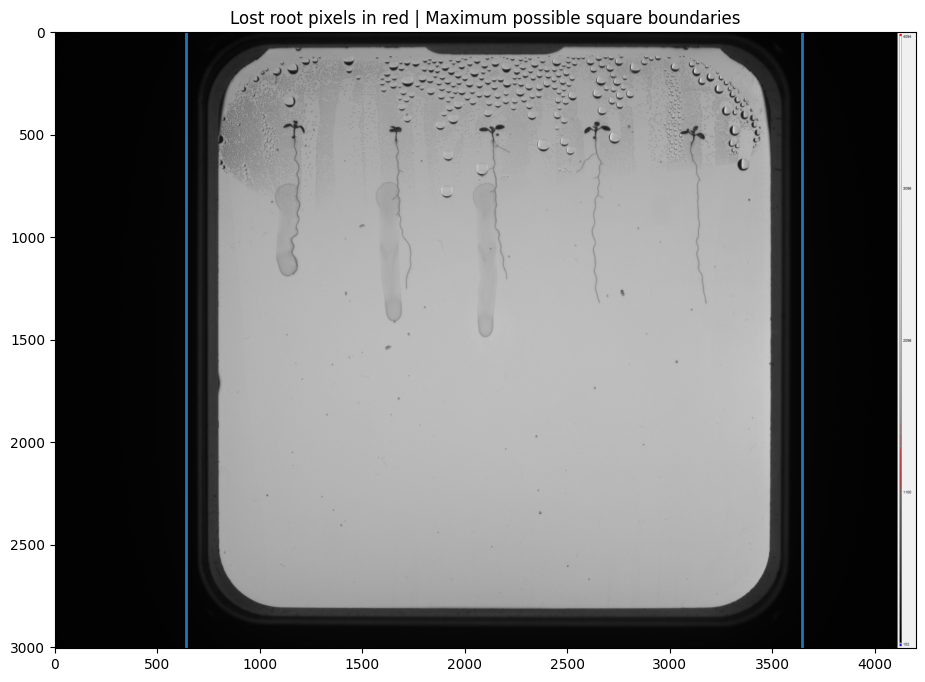

In [56]:
marked = cv2.cvtColor(
    image,
    cv2.COLOR_BGR2RGB
).copy()

# Make every lost labelled pixel bright and visible
marked[lost_root] = [255, 0, 0]

plt.figure(figsize=(18, 8))

plt.imshow(marked)

plt.axvline(
    l,
    linewidth=2
)

plt.axvline(
    r,
    linewidth=2
)

plt.title(
    "Lost root pixels in red | Maximum possible square boundaries"
)

plt.xlim(0, image.shape[1])
plt.ylim(image.shape[0], 0)

plt.show()

In [57]:
from pathlib import Path

PETRI_ROOT = BASE / "task4_petri_cropped"

petri_folders = {
    "train_images": PETRI_ROOT / "train_images",
    "train_masks": PETRI_ROOT / "train_masks",
    "val_images": PETRI_ROOT / "val_images",
    "val_masks": PETRI_ROOT / "val_masks",
}

# Prevent stale files from an older run
if PETRI_ROOT.exists():

    existing = [
        p for p in PETRI_ROOT.rglob("*")
        if p.is_file()
    ]

    if existing:
        raise RuntimeError(
            f"{PETRI_ROOT} already contains files. "
            "Delete or rename that folder before rerunning."
        )

for folder in petri_folders.values():
    folder.mkdir(parents=True, exist_ok=True)

print("✅ Petri output folders ready.")

✅ Petri output folders ready.


In [58]:
saved = 0

for split in ["train", "val"]:

    input_image_folder = folders[f"{split}_images"]

    image_paths = sorted([
        p for p in input_image_folder.iterdir()
        if p.is_file()
    ])

    for i, image_path in enumerate(image_paths):

        image_path, mask_path = find_pair(
            image_path.stem,
            split
        )

        image = cv2.imread(
            str(image_path),
            cv2.IMREAD_COLOR
        )

        mask = cv2.imread(
            str(mask_path),
            cv2.IMREAD_GRAYSCALE
        )

        if image is None or mask is None:
            raise ValueError(
                f"Could not load {image_path.stem}"
            )

        if image.shape[:2] != mask.shape:
            raise ValueError(
                f"Shape mismatch: {image_path.stem}"
            )

        edges = get_petri_edges(
            image,
            margin=20
        )

        l = edges["left"]
        t = edges["top"]
        r = edges["right"]
        b = edges["bottom"]

        image_crop = image[t:b, l:r]
        mask_crop = mask[t:b, l:r]

        if image_crop.shape[:2] != mask_crop.shape:
            raise ValueError(
                f"Crop mismatch: {image_path.stem}"
            )

        if image_crop.shape[0] != image_crop.shape[1]:
            raise ValueError(
                f"Crop not square: {image_path.stem}"
            )

        # Preserve binary mask values exactly as 0/1
        mask_crop = (mask_crop > 0).astype(np.uint8)

        output_image = (
            petri_folders[f"{split}_images"]
            / image_path.name
        )

        output_mask = (
            petri_folders[f"{split}_masks"]
            / mask_path.name
        )

        image_ok = cv2.imwrite(
            str(output_image),
            image_crop
        )

        mask_ok = cv2.imwrite(
            str(output_mask),
            mask_crop
        )

        if not image_ok or not mask_ok:
            raise IOError(
                f"Could not save {image_path.stem}"
            )

        saved += 1

        print(
            f"\rSaving {split}: "
            f"{i + 1}/{len(image_paths)}",
            end=""
        )

    print()

print("\n✅ Saved pairs:", saved)

Saving train: 105/314

[ WARN:0@1236.424] global grfmt_tiff.cpp:123 TIFF_Warning TIFFReadDirectory: Unknown field with tag 50838 (0xc696) encountered
[ WARN:0@1236.424] global grfmt_tiff.cpp:123 TIFF_Warning TIFFReadDirectory: Unknown field with tag 50839 (0xc697) encountered


Saving train: 106/314

[ WARN:0@1236.877] global grfmt_tiff.cpp:123 TIFF_Warning TIFFReadDirectory: Unknown field with tag 50838 (0xc696) encountered
[ WARN:0@1236.877] global grfmt_tiff.cpp:123 TIFF_Warning TIFFReadDirectory: Unknown field with tag 50839 (0xc697) encountered


Saving train: 107/314

[ WARN:0@1237.360] global grfmt_tiff.cpp:123 TIFF_Warning TIFFReadDirectory: Unknown field with tag 50838 (0xc696) encountered
[ WARN:0@1237.360] global grfmt_tiff.cpp:123 TIFF_Warning TIFFReadDirectory: Unknown field with tag 50839 (0xc697) encountered


... (29 outputs left out)

[ WARN:0@1342.449] global grfmt_tiff.cpp:123 TIFF_Warning TIFFReadDirectory: Unknown field with tag 50838 (0xc696) encountered
[ WARN:0@1342.449] global grfmt_tiff.cpp:123 TIFF_Warning TIFFReadDirectory: Unknown field with tag 50839 (0xc697) encountered


Saving val: 58/63

[ WARN:0@1359.108] global grfmt_tiff.cpp:123 TIFF_Warning TIFFReadDirectory: Unknown field with tag 50838 (0xc696) encountered
[ WARN:0@1359.108] global grfmt_tiff.cpp:123 TIFF_Warning TIFFReadDirectory: Unknown field with tag 50839 (0xc697) encountered


Saving val: 63/63

✅ Saved pairs: 377


In [59]:
for split, expected in [
    ("train", 314),
    ("val", 63)
]:

    image_count = len([
        p for p in petri_folders[f"{split}_images"].iterdir()
        if p.is_file()
    ])

    mask_count = len([
        p for p in petri_folders[f"{split}_masks"].iterdir()
        if p.is_file()
    ])

    print(f"\n{split.upper()}")
    print("Images:", image_count)
    print("Masks: ", mask_count)

    assert image_count == expected
    assert mask_count == expected

print("\n✅ All Petri crops accounted for.")


TRAIN
Images: 314
Masks:  314

VAL
Images: 63
Masks:  63

✅ All Petri crops accounted for.


In [61]:
def show_random_saved_petri(split="train"):

    image_folder = petri_folders[f"{split}_images"]
    mask_folder = petri_folders[f"{split}_masks"]

    image_path = random.choice([
        p for p in image_folder.iterdir()
        if p.is_file()
    ])

    mask_candidates = [
        p for p in mask_folder.iterdir()
        if p.is_file()
        and p.stem.lower()
        == f"{image_path.stem.lower()}_root_mask"
    ]

    if len(mask_candidates) != 1:
        raise ValueError(
            f"Expected one mask, found {len(mask_candidates)}"
        )

    mask_path = mask_candidates[0]

    image = cv2.imread(
        str(image_path),
        cv2.IMREAD_COLOR
    )

    mask = cv2.imread(
        str(mask_path),
        cv2.IMREAD_GRAYSCALE
    )

    print("Image:", image_path.name)
    print("Mask:", mask_path.name)
    print("Image shape:", image.shape)
    print("Mask shape:", mask.shape)
    print("Mask values:", np.unique(mask))

    assert image.shape[:2] == mask.shape
    assert image.shape[0] == image.shape[1]
    assert set(np.unique(mask)).issubset({0, 1})

    root = mask > 0

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(16, 5)
    )

    axes[0].imshow(
        cv2.cvtColor(
            image,
            cv2.COLOR_BGR2RGB
        )
    )
    axes[0].set_title("Saved Petri image")

    axes[1].imshow(
        mask,
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[1].set_title("Saved root mask")

    axes[2].imshow(
        cv2.cvtColor(
            image,
            cv2.COLOR_BGR2RGB
        )
    )

    axes[2].imshow(
        np.ma.masked_where(
            ~root,
            root
        ),
        cmap="Reds",
        alpha=0.6
    )

    axes[2].set_title("Saved overlay")

    plt.tight_layout()
    plt.show()

Image: train_Shival_231781_im1.png
Mask: train_Shival_231781_im1_root_mask.tif
Image shape: (2735, 2735, 3)
Mask shape: (2735, 2735)
Mask values: [0 1]


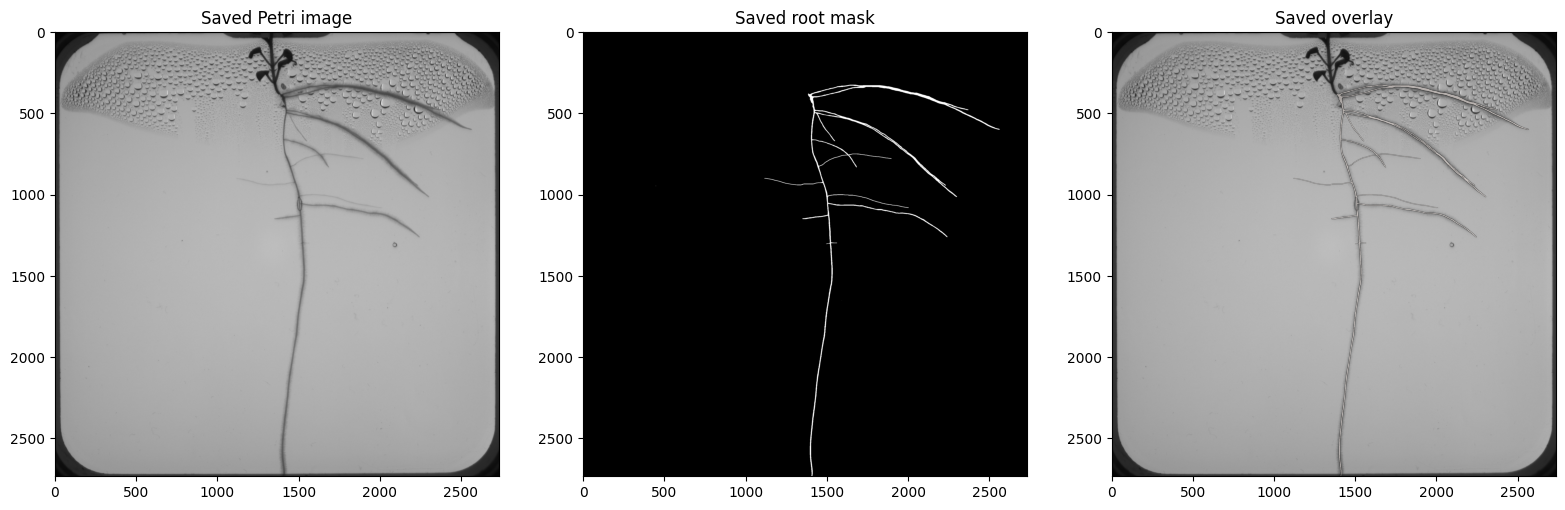

In [62]:
show_random_saved_petri("train")

Image: train_Alican_242845_im1.png
Mask: train_Alican_242845_im1_root_mask.tif
Image shape: (2735, 2735, 3)
Mask shape: (2735, 2735)
Mask values: [0 1]


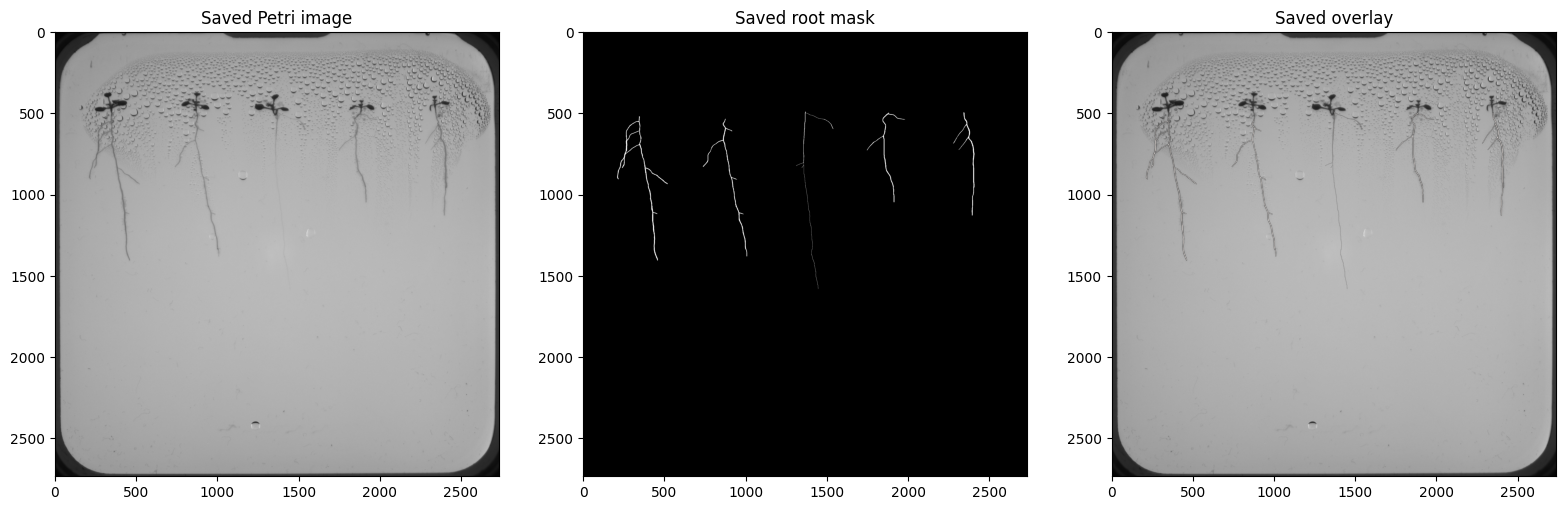

In [63]:
show_random_saved_petri("val")

In [64]:
from pathlib import Path
import cv2
import numpy as np
import pandas as pd

cropped_images_dir = Path("cropped_images")
cropped_masks_dir = Path("cropped_masks")

image_files = sorted(cropped_images_dir.glob("*.png"))

records = []

for image_path in image_files:
    mask_path = cropped_masks_dir / image_path.name

    image = cv2.imread(str(image_path))
    mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)

    if image is None or mask is None:
        continue

    h, w = image.shape[:2]

    root_pixels = np.count_nonzero(mask)
    total_pixels = mask.size
    root_percentage = (root_pixels / total_pixels) * 100

    records.append({
        "filename": image_path.name,
        "height": h,
        "width": w,
        "aspect_ratio": w / h,
        "root_pixels": root_pixels,
        "root_percentage": root_percentage
    })

df = pd.DataFrame(records)

print("Number of pairs:", len(df))

print("\nHEIGHT")
print(df["height"].describe())

print("\nWIDTH")
print(df["width"].describe())

print("\nROOT PIXEL %")
print(df["root_percentage"].describe())

Number of pairs: 0

HEIGHT


KeyError: 'height'

In [65]:
from pathlib import Path

root = Path("task4_petri_cropped")

train_images_dir = root / "train_images"
train_masks_dir  = root / "train_masks"

val_images_dir = root / "val_images"
val_masks_dir  = root / "val_masks"

print("Train images:", len(list(train_images_dir.glob("*.png"))))
print("Train masks:", len(list(train_masks_dir.glob("*.png"))))
print("Val images:", len(list(val_images_dir.glob("*.png"))))
print("Val masks:", len(list(val_masks_dir.glob("*.png"))))

Train images: 314
Train masks: 0
Val images: 63
Val masks: 0


In [68]:
import cv2
import numpy as np
import pandas as pd

def analyse_dataset(images_dir, masks_dir, split_name):

    records = []

    image_files = sorted(images_dir.glob("*.png"))

    for image_path in image_files:

        # image: xxx.png
        # mask:  xxx_root_mask.tif
        mask_path = masks_dir / f"{image_path.stem}_root_mask.tif"

        image = cv2.imread(str(image_path))
        mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)

        if image is None:
            print("Could not read image:", image_path.name)
            continue

        if mask is None:
            print("Could not read mask:", mask_path.name)
            continue

        # Check image and mask still align
        if image.shape[:2] != mask.shape[:2]:
            print(
                "Shape mismatch:",
                image_path.name,
                image.shape[:2],
                mask.shape[:2]
            )
            continue

        h, w = image.shape[:2]

        root_pixels = np.count_nonzero(mask)
        root_percentage = (root_pixels / mask.size) * 100

        records.append({
            "split": split_name,
            "filename": image_path.name,
            "height": h,
            "width": w,
            "aspect_ratio": w / h,
            "root_pixels": root_pixels,
            "root_percentage": root_percentage
        })

    return pd.DataFrame(records)


train_df = analyse_dataset(
    train_images_dir,
    train_masks_dir,
    "train"
)

val_df = analyse_dataset(
    val_images_dir,
    val_masks_dir,
    "validation"
)

df = pd.concat([train_df, val_df], ignore_index=True)

print("Train pairs:", len(train_df))
print("Validation pairs:", len(val_df))
print("Total pairs:", len(df))

print("\nHEIGHT")
print(df["height"].describe())

print("\nWIDTH")
print(df["width"].describe())

print("\nROOT PIXEL PERCENTAGE")
print(df["root_percentage"].describe())

Train pairs: 314
Validation pairs: 63
Total pairs: 377

HEIGHT
count     377.000000
mean     2748.098143
std        10.460586
min      2720.000000
25%      2735.000000
50%      2756.000000
75%      2756.000000
max      2757.000000
Name: height, dtype: float64

WIDTH
count     377.000000
mean     2748.098143
std        10.460586
min      2720.000000
25%      2735.000000
50%      2756.000000
75%      2756.000000
max      2757.000000
Name: width, dtype: float64

ROOT PIXEL PERCENTAGE
count    377.000000
mean       0.407961
std        0.434388
min        0.000000
25%        0.121953
50%        0.262562
75%        0.524138
max        2.770619
Name: root_percentage, dtype: float64


In [69]:
import math
import pandas as pd
import cv2
import numpy as np

PATCH_SIZES = [128, 256, 512]

def evaluate_patch_size(images_dir, masks_dir, patch_size):

    total_patches = 0
    root_patches = 0
    empty_patches = 0
    root_percentages = []

    image_files = sorted(images_dir.glob("*.png"))

    for image_path in image_files:

        mask_path = masks_dir / f"{image_path.stem}_root_mask.tif"

        mask = cv2.imread(
            str(mask_path),
            cv2.IMREAD_GRAYSCALE
        )

        if mask is None:
            continue

        h, w = mask.shape

        padded_h = math.ceil(h / patch_size) * patch_size
        padded_w = math.ceil(w / patch_size) * patch_size

        padded = np.zeros(
            (padded_h, padded_w),
            dtype=mask.dtype
        )

        padded[:h, :w] = mask

        for y in range(0, padded_h, patch_size):
            for x in range(0, padded_w, patch_size):

                patch = padded[
                    y:y + patch_size,
                    x:x + patch_size
                ]

                total_patches += 1

                root_pixels = np.count_nonzero(patch)

                if root_pixels > 0:
                    root_patches += 1
                    root_percentages.append(
                        root_pixels / patch.size * 100
                    )
                else:
                    empty_patches += 1

    return {
        "patch_size": patch_size,
        "total_patches": total_patches,
        "root_patches": root_patches,
        "empty_patches": empty_patches,
        "empty_percentage":
            empty_patches / total_patches * 100,
        "mean_root_%_positive_patches":
            np.mean(root_percentages)
            if root_percentages else 0
    }


results = []

for size in PATCH_SIZES:

    result = evaluate_patch_size(
        train_images_dir,
        train_masks_dir,
        size
    )

    results.append(result)

results_df = pd.DataFrame(results)

display(results_df)

,patch_size,total_patches,root_patches,empty_patches,empty_percentage,mean_root_%_positive_patches
0,128,151976,14549,137427,90.426778,4.061927
1,256,37994,6360,31634,83.260515,2.322994
2,512,11304,3280,8024,70.983723,1.126086


In [70]:
empty_masks = train_df[
    train_df["root_percentage"] == 0
]

print("Completely empty training masks:", len(empty_masks))

display(
    empty_masks[
        ["filename", "root_percentage"]
    ]
)

Completely empty training masks: 11


,filename,root_percentage
215,train_Shival_211066_im4.png,0.0
220,train_Shival_230036_im4.png,0.0
229,train_Shival_231265_im4.png,0.0
234,train_Shival_231781_im4.png,0.0
239,train_Shival_232166_im4.png,0.0
248,train_Shival_233182_im4.png,0.0
262,train_Shival_234924_im4.png,0.0
287,val_Myrthe_221989_im4.png,0.0
302,val_Myrthe_232969_im4.png,0.0
307,val_Myrthe_233650_im4.png,0.0


In [ ]:
512.512 gives only 71% empty, 128 90% would be empty

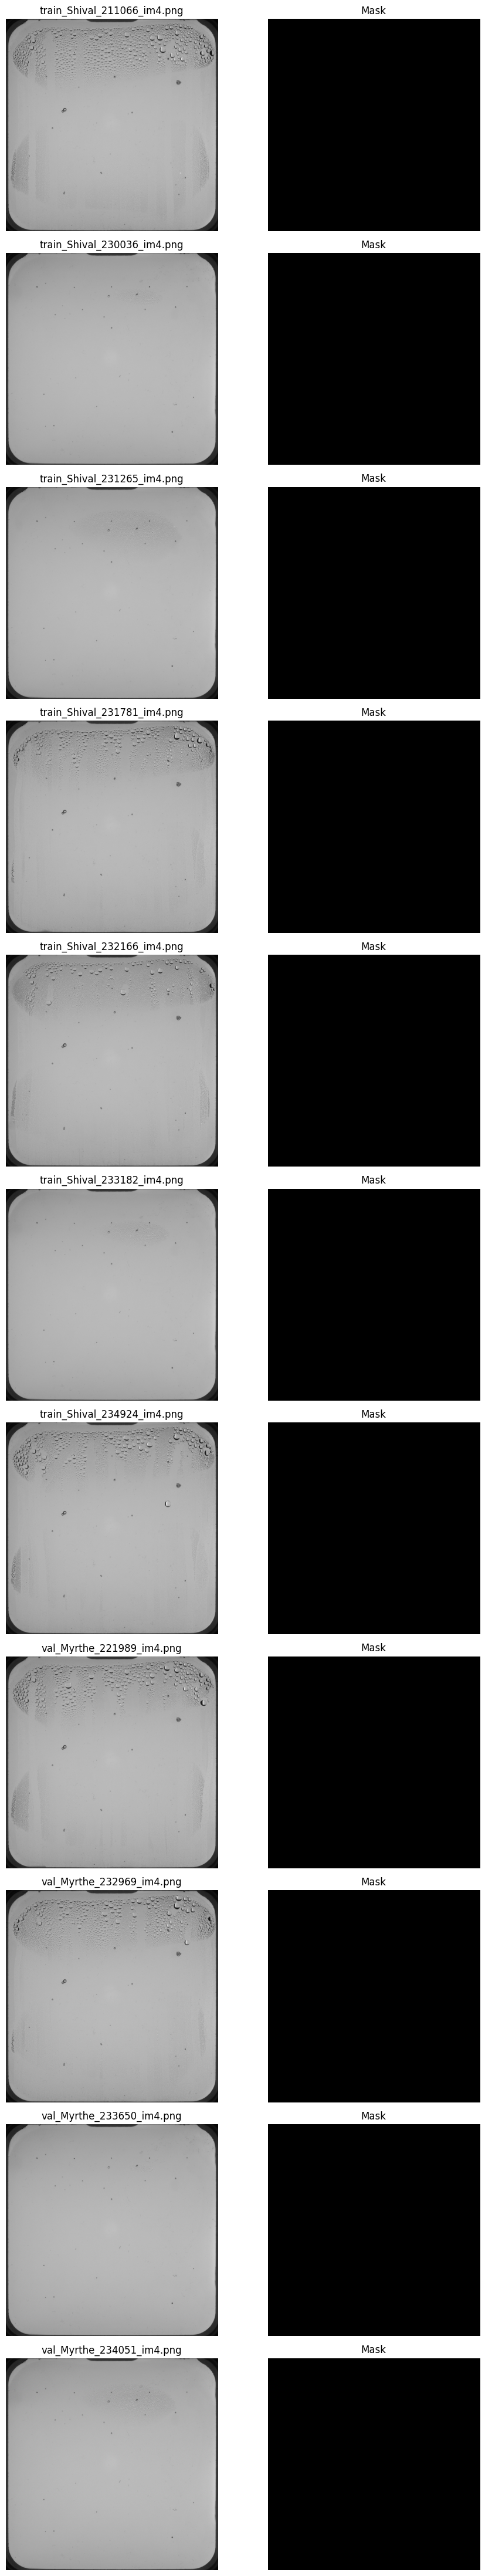

In [71]:
import matplotlib.pyplot as plt

empty_files = empty_masks["filename"].tolist()

fig, axes = plt.subplots(
    len(empty_files),
    2,
    figsize=(10, 4 * len(empty_files))
)

for i, filename in enumerate(empty_files):

    image_path = train_images_dir / filename
    mask_path = train_masks_dir / f"{Path(filename).stem}_root_mask.tif"

    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    mask = cv2.imread(
        str(mask_path),
        cv2.IMREAD_GRAYSCALE
    )

    axes[i, 0].imshow(image)
    axes[i, 0].set_title(filename)
    axes[i, 0].axis("off")

    axes[i, 1].imshow(mask, cmap="gray")
    axes[i, 1].set_title("Mask")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

In [74]:
root = Path("task4_petri_cropped")

train_images_dir = root / "train_images"
train_masks_dir  = root / "train_masks"

val_images_dir = root / "val_images"
val_masks_dir  = root / "val_masks"

output_root = Path("task4_patches_512_balanced")

train_out_images = output_root / "train" / "images"
train_out_masks  = output_root / "train" / "masks"

val_out_images = output_root / "val" / "images"
val_out_masks  = output_root / "val" / "masks"

for folder in [
    train_out_images, train_out_masks,
    val_out_images, val_out_masks
]:
    folder.mkdir(parents=True, exist_ok=True)

PATCH_SIZE = 512
RANDOM_SEED = 42
random.seed(RANDOM_SEED)

In [75]:
def read_image_mask(image_path, masks_dir):
    mask_path = masks_dir / f"{image_path.stem}_root_mask.tif"

    image = cv2.imread(str(image_path))
    mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)

    if image is None:
        raise ValueError(f"Could not read image: {image_path}")

    if mask is None:
        raise ValueError(f"Could not read mask: {mask_path}")

    if image.shape[:2] != mask.shape[:2]:
        raise ValueError(
            f"Shape mismatch for {image_path.name}: "
            f"{image.shape[:2]} vs {mask.shape[:2]}"
        )

    mask = (mask > 0).astype(np.uint8) * 255
    return image, mask


def pad_pair(image, mask, patch_size=512):
    h, w = image.shape[:2]

    pad_h = (patch_size - h % patch_size) % patch_size
    pad_w = (patch_size - w % patch_size) % patch_size

    top = pad_h // 2
    bottom = pad_h - top
    left = pad_w // 2
    right = pad_w - left

    padded_image = cv2.copyMakeBorder(
        image, top, bottom, left, right,
        borderType=cv2.BORDER_CONSTANT,
        value=(0, 0, 0)
    )

    padded_mask = cv2.copyMakeBorder(
        mask, top, bottom, left, right,
        borderType=cv2.BORDER_CONSTANT,
        value=0
    )

    return padded_image, padded_mask


def save_patch(image_patch, mask_patch, out_image_path, out_mask_path):
    cv2.imwrite(str(out_image_path), image_patch)
    cv2.imwrite(str(out_mask_path), mask_patch)

In [76]:
train_image_files = sorted(train_images_dir.glob("*.png"))

positive_count = 0
empty_candidates = []

for image_path in train_image_files:
    image, mask = read_image_mask(image_path, train_masks_dir)
    image, mask = pad_pair(image, mask, PATCH_SIZE)

    h, w = image.shape[:2]
    patch_idx = 0

    for y in range(0, h, PATCH_SIZE):
        for x in range(0, w, PATCH_SIZE):
            image_patch = image[y:y+PATCH_SIZE, x:x+PATCH_SIZE]
            mask_patch = mask[y:y+PATCH_SIZE, x:x+PATCH_SIZE]

            patch_name = f"{image_path.stem}_patch_{patch_idx:03d}.png"

            if np.count_nonzero(mask_patch) > 0:
                save_patch(
                    image_patch,
                    mask_patch,
                    train_out_images / patch_name,
                    train_out_masks / patch_name
                )
                positive_count += 1
            else:
                empty_candidates.append((image_path, y, x, patch_idx))

            patch_idx += 1

print("Positive training patches saved:", positive_count)
print("Empty training patch candidates:", len(empty_candidates))

Positive training patches saved: 2763
Empty training patch candidates: 8541


In [77]:
num_empty_to_keep = min(positive_count, len(empty_candidates))
selected_empty = random.sample(empty_candidates, num_empty_to_keep)

for image_path, y, x, patch_idx in selected_empty:
    image, mask = read_image_mask(image_path, train_masks_dir)
    image, mask = pad_pair(image, mask, PATCH_SIZE)

    image_patch = image[y:y+PATCH_SIZE, x:x+PATCH_SIZE]
    mask_patch = mask[y:y+PATCH_SIZE, x:x+PATCH_SIZE]

    patch_name = f"{image_path.stem}_patch_{patch_idx:03d}.png"

    save_patch(
        image_patch,
        mask_patch,
        train_out_images / patch_name,
        train_out_masks / patch_name
    )

print("Empty training patches kept:", num_empty_to_keep)
print("Total saved training patches:", positive_count + num_empty_to_keep)

Empty training patches kept: 2763
Total saved training patches: 5526


In [78]:
val_image_files = sorted(val_images_dir.glob("*.png"))

val_total = 0
val_positive = 0
val_empty = 0

for image_path in val_image_files:
    image, mask = read_image_mask(image_path, val_masks_dir)
    image, mask = pad_pair(image, mask, PATCH_SIZE)

    h, w = image.shape[:2]
    patch_idx = 0

    for y in range(0, h, PATCH_SIZE):
        for x in range(0, w, PATCH_SIZE):
            image_patch = image[y:y+PATCH_SIZE, x:x+PATCH_SIZE]
            mask_patch = mask[y:y+PATCH_SIZE, x:x+PATCH_SIZE]

            patch_name = f"{image_path.stem}_patch_{patch_idx:03d}.png"

            save_patch(
                image_patch,
                mask_patch,
                val_out_images / patch_name,
                val_out_masks / patch_name
            )

            val_total += 1
            if np.count_nonzero(mask_patch) > 0:
                val_positive += 1
            else:
                val_empty += 1

            patch_idx += 1

print("Validation patches saved:", val_total)
print("Validation positive patches:", val_positive)
print("Validation empty patches:", val_empty)

Validation patches saved: 2268
Validation positive patches: 828
Validation empty patches: 1440


In [79]:
print("TRAIN IMAGE PATCHES:", len(list(train_out_images.glob("*.png"))))
print("TRAIN MASK PATCHES: ", len(list(train_out_masks.glob("*.png"))))

print("VAL IMAGE PATCHES:  ", len(list(val_out_images.glob("*.png"))))
print("VAL MASK PATCHES:   ", len(list(val_out_masks.glob("*.png"))))

TRAIN IMAGE PATCHES: 5526
TRAIN MASK PATCHES:  5526
VAL IMAGE PATCHES:   2268
VAL MASK PATCHES:    2268


Image patch shape: (512, 512, 3)
Mask patch shape: (512, 512)
Mask unique values: [  0 255]


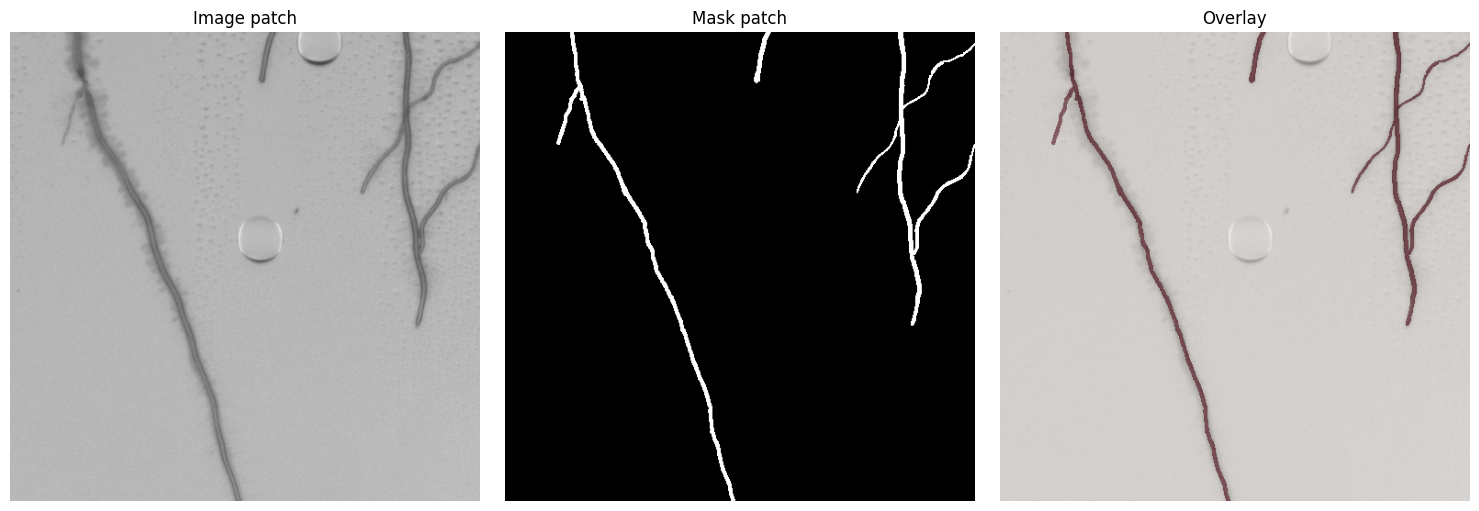

In [80]:
train_patch_files = sorted(train_out_images.glob("*.png"))
sample_patch = random.choice(train_patch_files)

image_patch = cv2.imread(str(sample_patch))
image_patch = cv2.cvtColor(image_patch, cv2.COLOR_BGR2RGB)

mask_patch = cv2.imread(
    str(train_out_masks / sample_patch.name),
    cv2.IMREAD_GRAYSCALE
)

print("Image patch shape:", image_patch.shape)
print("Mask patch shape:", mask_patch.shape)
print("Mask unique values:", np.unique(mask_patch))

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image_patch)
axes[0].set_title("Image patch")
axes[0].axis("off")

axes[1].imshow(mask_patch, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Mask patch")
axes[1].axis("off")

axes[2].imshow(image_patch)
axes[2].imshow(mask_patch, cmap="Reds", alpha=0.4, vmin=0, vmax=255)
axes[2].set_title("Overlay")
axes[2].axis("off")

plt.tight_layout()
plt.show()

In [81]:
train_imgs = {p.name for p in train_out_images.glob("*.png")}
train_msks = {p.name for p in train_out_masks.glob("*.png")}

val_imgs = {p.name for p in val_out_images.glob("*.png")}
val_msks = {p.name for p in val_out_masks.glob("*.png")}

print("Train image patches:", len(train_imgs))
print("Train mask patches:", len(train_msks))
print("Train pairs match:", train_imgs == train_msks)

print()

print("Validation image patches:", len(val_imgs))
print("Validation mask patches:", len(val_msks))
print("Validation pairs match:", val_imgs == val_msks)

print()

print("Overlap between train and validation:",
      len(train_imgs.intersection(val_imgs)))

Train image patches: 5526
Train mask patches: 5526
Train pairs match: True

Validation image patches: 2268
Validation mask patches: 2268
Validation pairs match: True

Overlap between train and validation: 0


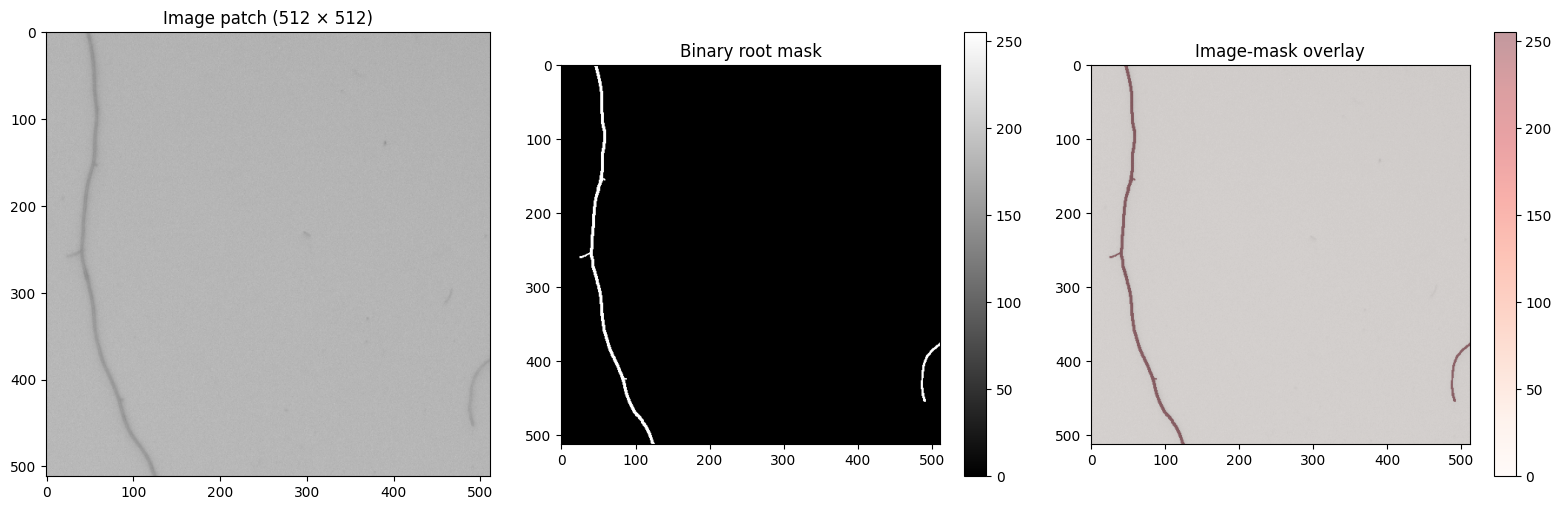

In [82]:
sample_patch = random.choice(
    [p for p in train_out_images.glob("*.png")]
)

image = cv2.imread(str(sample_patch))
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

mask = cv2.imread(
    str(train_out_masks / sample_patch.name),
    cv2.IMREAD_GRAYSCALE
)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

im0 = axes[0].imshow(image)
axes[0].set_title("Image patch (512 × 512)")

im1 = axes[1].imshow(mask, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Binary root mask")
plt.colorbar(im1, ax=axes[1])

axes[2].imshow(image)
im2 = axes[2].imshow(
    mask,
    cmap="Reds",
    alpha=0.4,
    vmin=0,
    vmax=255
)
axes[2].set_title("Image-mask overlay")
plt.colorbar(im2, ax=axes[2])

plt.tight_layout()
plt.show()

Patch: train_Elavendan_232345_im2_patch_007.png
Image shape: (512, 512, 3)
Mask shape: (512, 512)
Mask pixel values: [  0 255]


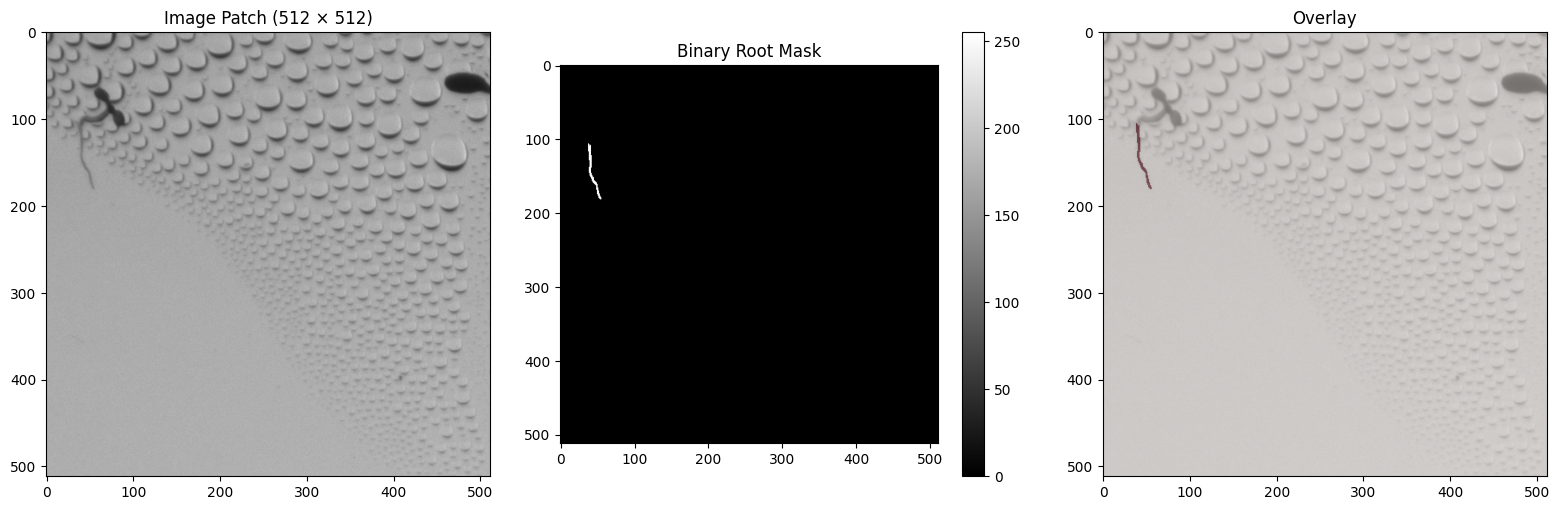

In [84]:
sample_patch = random.choice(
    [p for p in train_out_images.glob("*.png")
     if np.count_nonzero(
         cv2.imread(
             str(train_out_masks / p.name),
             cv2.IMREAD_GRAYSCALE
         )
     ) > 0]
)

image = cv2.imread(str(sample_patch))
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

mask = cv2.imread(
    str(train_out_masks / sample_patch.name),
    cv2.IMREAD_GRAYSCALE
)

print("Patch:", sample_patch.name)
print("Image shape:", image.shape)
print("Mask shape:", mask.shape)
print("Mask pixel values:", np.unique(mask))

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(image)
axes[0].set_title("Image Patch (512 × 512)")

m = axes[1].imshow(mask, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Binary Root Mask")
plt.colorbar(m, ax=axes[1])

axes[2].imshow(image)
axes[2].imshow(mask, cmap="Reds", alpha=0.4, vmin=0, vmax=255)
axes[2].set_title("Overlay")

plt.tight_layout()
plt.show()

Dataset preparation: The cropped Petri dish images were approximately 2750 × 2750 pixels. Patch sizes of 128, 256 and 512 pixels were evaluated. Since root pixels represented only approximately 0.41% of the image pixels, smaller patch sizes produced a very high proportion of empty patches. A patch size of 512 × 512 was therefore selected to retain more spatial context and reduce the number of empty patches. Images and masks were padded where necessary rather than resized. All root-containing training patches were retained and an equal number of randomly selected background patches were included to reduce class imbalance. The validation set retained its natural distribution. All masks are binary with pixel values of 0 and 255.

In [85]:
from pathlib import Path
import shutil

final_root = Path("task4_dataset")

final_train_images = final_root / "train_images" / "train"
final_train_masks  = final_root / "train_masks" / "train"

final_val_images = final_root / "val_images" / "val"
final_val_masks  = final_root / "val_masks" / "val"

for folder in [
    final_train_images,
    final_train_masks,
    final_val_images,
    final_val_masks
]:
    folder.mkdir(parents=True, exist_ok=True)


def copy_folder(source, destination):
    for file in source.glob("*.png"):
        shutil.copy2(file, destination / file.name)


copy_folder(train_out_images, final_train_images)
copy_folder(train_out_masks, final_train_masks)

copy_folder(val_out_images, final_val_images)
copy_folder(val_out_masks, final_val_masks)

print("Train images:", len(list(final_train_images.glob("*.png"))))
print("Train masks:", len(list(final_train_masks.glob("*.png"))))
print("Validation images:", len(list(final_val_images.glob("*.png"))))
print("Validation masks:", len(list(final_val_masks.glob("*.png"))))

Train images: 5526
Train masks: 5526
Validation images: 2268
Validation masks: 2268


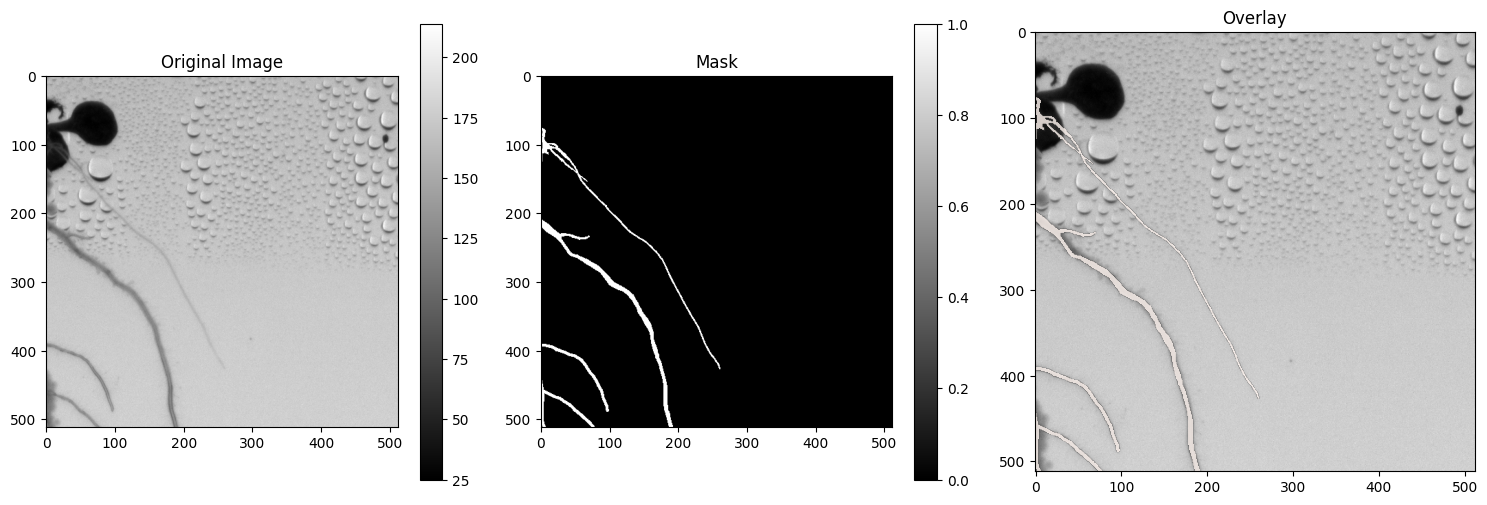

Image shape: (512, 512)
Mask shape: (512, 512)
Original stored mask values: [  0 255]


In [87]:
import random
import cv2
import numpy as np
import matplotlib.pyplot as plt

sample_path = random.choice(list(final_train_images.glob("*.png")))

image = cv2.imread(str(sample_path), cv2.IMREAD_GRAYSCALE)

mask = cv2.imread(
    str(final_train_masks / sample_path.name),
    cv2.IMREAD_GRAYSCALE
)

# Convert mask to 0/1 for display like the example
mask_binary = (mask > 0).astype(np.uint8)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Original image
im1 = axes[0].imshow(image, cmap="gray")
axes[0].set_title("Original Image")
plt.colorbar(im1, ax=axes[0])

# Mask
im2 = axes[1].imshow(
    mask_binary,
    cmap="gray",
    vmin=0,
    vmax=1
)
axes[1].set_title("Mask")
plt.colorbar(im2, ax=axes[1])

# Overlay
axes[2].imshow(image, cmap="gray")
overlay = axes[2].imshow(
    np.ma.masked_where(mask_binary == 0, mask_binary),
    cmap="Reds",
    alpha=0.8
)
axes[2].set_title("Overlay")

plt.tight_layout()
plt.show()

print("Image shape:", image.shape)
print("Mask shape:", mask.shape)
print("Original stored mask values:", np.unique(mask))